# Lab book: biathlon sprint prediction

Every check has its own cell, with a short text above it that says what is checked and what we expect.

How to use it: run the import cell below once. After that, any single check cell can be run alone.

All data comes from functions in `pipeline.py`. The test seasons (2023/24, 2024/25, 2025/26) stay closed: the function `open_seasons` of `pipeline.py` removes them right after loading. Only their row and race counts are shown.

In [1]:
# IMPORT CELL: run this one first. Every other cell only needs this one.
import numpy as np
import pandas as pd
import pipeline as p

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)


# 2 helpers of pipeline.py that almost every cell uses:
# open_seasons(table) removes the test seasons from a table,
# load_fin() rebuilds the working table of step 2 without the test seasons.
from pipeline import open_seasons, load_fin

# Section 1: The data

## 1.0 Why there are 2 raw files

`data/sprints_raw.csv` holds the sprints only: results plus split times (ski time CRST, range time RNGT and their parts). It feeds the target and the ski and range features.

`data/races_all.csv` holds every level 1 race of every format, relays included: results only, no split times. It feeds the load features (race days, days since the last race, missed event, first start at a major event) and the last race feature.

Both files cover the seasons 2012/13 to 2025/26, World Cup, World Championships and Olympics. No IBU Cup.

**Which script made which file, and with which command.** All commands are run in the project folder, after `conda activate biathlon`.

* `data/sprints_raw.csv` is made by `download_sprints.py`, with the command `python download_sprints.py`.
* `data/races_all.csv` is made by `download_races.py`, with the command `python download_races.py`.
* `data/features.csv` is made by `pipeline.py` from the 2 files above, with the command `python pipeline.py features`.

Notes.

* `data/sprints_raw.csv` was made on 6 October 2026 by the cells of the notebook `01_explore.ipynb`. The same code now lives in `download_sprints.py`. The script has not been run since the move. Running it writes the file again.
* `download_races.py` also keeps 1 small file per race in `data/races_parts/` (its saved progress). From its next run on it will also save the list of cancelled races in `data/races_cancelled.csv`. That file does not exist yet.
* Nothing in `data/` goes to git.

**Check: size of the 2 files per season.** Expected: 14 seasons in both files. For the 3 test seasons this table is the only thing we look at.

In [2]:
sprints = p.load_sprints()
races = p.load_races()
table = pd.DataFrame({
    "sprint file rows": sprints.groupby("season").size(),
    "sprint file races": sprints.groupby("season")["race_id"].nunique(),
    "all races file rows": races.groupby("season").size(),
    "all races file races": races.groupby("season")["race_id"].nunique(),
})
table["test season"] = table.index.isin(p.TEST_SEASONS)
print(table)

        sprint file rows  sprint file races  all races file rows  all races file races  test season
season                                                                                             
1213                2053                 20                 5285                    66        False
1314                1918                 20                 4797                    63        False
1415                1984                 20                 5224                    66        False
1516                1767                 18                 5007                    65        False
1617                1845                 18                 5289                    67        False
1718                1781                 18                 5060                    67        False
1819                1852                 18                 5246                    66        False
1920                1681                 16                 5023                    60        False


**Check: the sprint rows are the same in both files.** We put the sprint rows of the 2 files side by side, matched on race and athlete. Expected: every row has a partner, and rank, status, total time, gap, misses and nation are equal. The name may differ for a few athletes who changed their name between the 2 downloads (the athlete code is the same).

In [3]:
sprints = open_seasons(p.load_sprints())
races = open_seasons(p.load_races())
races_sp = races[races["discipline"] == "SP"]

both = sprints.merge(races_sp, on=["race_id", "IBUId"], how="outer",
                     suffixes=("_s", "_r"), indicator=True)
print("rows in the sprint file         :", len(sprints))
print("sprint rows in the all races file:", len(races_sp))
print("rows without a partner          :", (both["_merge"] != "both").sum())

# Count the rows where a column differs (2 empty cells count as equal).
both["ShootingTotal_r"] = pd.to_numeric(both["ShootingTotal_r"])
for col in ["Rank", "IRM", "TotalTime", "Behind", "ShootingTotal", "Nat", "start", "Name"]:
    a = both[col + "_s"]
    b = both[col + "_r"]
    different = (a != b) & ~(a.isna() & b.isna())
    print(f"{col:<14} different in {different.sum():>3} rows")

names = both[both["Name_s"] != both["Name_r"]]
print()
print(names[["IBUId", "Name_s", "Name_r"]].drop_duplicates().to_string(index=False))

rows in the sprint file         : 20622
sprint rows in the all races file: 20622
rows without a partner          : 0
Rank           different in   0 rows
IRM            different in   0 rows
TotalTime      different in   0 rows
Behind         different in   0 rows
ShootingTotal  different in   0 rows
Nat            different in   0 rows
start          different in   0 rows
Name           different in  28 rows

           IBUId      Name_s      Name_r
BTCAN20512198201 KOCHER Zina LAWSON Zina


## File 1: sprints_raw.csv

### 1.1 Documented cases (sprint file)

These cases are complex but clean: the data says clearly what happened, and we chose a rule for each.

**DNS (did not start).** Rule: the row is not predicted. It is not a race day and it never enters any feature.

**DNF (did not finish) and DSQ (disqualified).** Rule: the row is not predicted, because there is no valid finish place. The athlete did race, so it is a race day for the load features. The sprint features (1 to 6, 8, 13) skip it.

**Check: DNS, DNF and DSQ per season.** Expected: a small share, a few dozen per season, and no other status word.

In [4]:
sprints = open_seasons(p.load_sprints())
status = sprints["IRM"].fillna("finisher")
table = pd.crosstab(sprints["season"], status, margins=True)
print(table)
print()
print("share of rows that are not finishers:", round((status != "finisher").mean(), 4))

IRM     DNF  DNS  DSQ  finisher    All
season                                
1213      9   32   16      1996   2053
1314     12   26   38      1842   1918
1415     11   32   13      1928   1984
1516      4   29    4      1730   1767
1617      2   23    5      1815   1845
1718      5   25    0      1751   1781
1819      7   31    1      1813   1852
1920      3   22    1      1655   1681
2021      6   13    8      2060   2087
2122      9   28    2      2017   2056
2223      5   20    1      1572   1598
All      73  281   89     20179  20622

share of rows that are not finishers: 0.0215


**Lapped relay teams.** This case does not exist in the sprint file: a sprint is an individual race and nobody is lapped.

**Check: no lapped rows in the sprint file.** Expected: 0 rows with the status LAP and 0 rows with the word Lapped as total time.

In [5]:
sprints = open_seasons(p.load_sprints())
print("rows with status LAP          :", (sprints["IRM"] == "LAP").sum())
print("rows with 'Lapped' as total time:", (sprints["TotalTime"] == "Lapped").sum())

rows with status LAP          : 0
rows with 'Lapped' as total time: 0


**Cancelled races.** Rule: a cancelled race has no rows at all. The download kept only races with the status Final. The list of the 16 cancelled races was printed by `download_races.py` at the end of the download. It is kept once, as the constant `CANCELLED_RACES` in `pipeline.py`. 4 of the 16 are sprints (Canmore 2019 and Oslo 2020).

**Check: cancelled sprints are absent.** Expected: every race in the file has the status Final, and the 4 cancelled sprints are not in the file.

In [6]:
sprints = open_seasons(p.load_sprints())
print(sprints.drop_duplicates("race_id")["status"].value_counts())

# The cancelled races are listed in pipeline.py. A sprint has an ID that ends with "SP".
cancelled_sprints = [race_id for race_id in p.CANCELLED_RACES if race_id.endswith("SP")]
print("cancelled sprints in the list      :", cancelled_sprints)
print("cancelled sprints found in the file:", sprints["race_id"].isin(cancelled_sprints).sum())

status
Final    204
Name: count, dtype: int64
cancelled sprints in the list      : ['BT1819SWRLCP07SMSP', 'BT1819SWRLCP07SWSP', 'BT1920SWRLCP09SWSP', 'BT1920SWRLCP09SMSP']
cancelled sprints found in the file: 0


### 1.2 Dirty data (sprint file, finishers only)

Dirty means: the value is missing or cannot be true. From here on we only look at finishers (status empty), because only they are predicted.

**Check: empty values per column per season.** Expected: none. Only columns with at least 1 empty value are shown.

In [7]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]
cols = ["IBUId", "Name", "Nat", "Bib", "Rank", "Shootings", "ShootingTotal", "TotalTime",
        "Behind", "CRST", "RNGT", "STTM", "CRS1", "CRS2", "CRS3", "RNG1", "RNG2",
        "start", "gender"]
empty = fin[cols].isna().groupby(fin["season"]).sum()
print(empty.loc[:, empty.sum() > 0])        # only the columns with an empty value

rows = fin[fin[cols].isna().any(axis=1)]
print()
print(rows[["race_id", "Name", "Rank", "TotalTime", "CRST", "RNGT", "STTM", "CRS1", "RNG1"]].to_string(index=False))

        CRST  RNGT  STTM  CRS1  CRS2  CRS3  RNG1  RNG2
season                                                
1213       0     0     0     0     0     0     0     0
1314       0     0     0     0     0     0     0     0
1415       0     0     0     0     0     0     0     0
1516       0     0     0     0     0     0     0     0
1617       0     0     0     0     0     0     0     0
1718       0     0     0     0     0     0     0     0
1819       0     0     0     0     0     0     0     0
1920       0     0     1     0     0     0     0     0
2021       3     3     0     1     3     3     1     3
2122       0     0     0     0     0     0     0     0
2223       0     0     0     0     0     0     0     0

           race_id             Name  Rank TotalTime    CRST   RNGT   STTM   CRS1   RNG1
BT1920SWRLCP03SMSP      DOVZAN Miha  50.0   25:18.2 23:51.5 1:26.6    NaN 8:02.9   46.8
BT2021SWRLCP03SWSP SCHNEIDER Sophia  80.0   22:48.4     NaN    NaN 1:03.6    NaN    NaN
BT2021SWRLCP03SWSP  

**Check: does the rank follow the total time?** We rank the total times inside each race ourselves and compare with the rank of the file. Expected: 0 differences. We also check that the gap to the winner (Behind) equals total time minus the time of the winner.

In [8]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]
our_rank = fin.groupby("race_id")["TotalTime_s"].rank(method="min")
print("rows where the rank does not follow the time:", (our_rank != fin["Rank"]).sum())

winner_time = fin.groupby("race_id")["TotalTime_s"].transform("min")
gap_error = (fin["TotalTime_s"] - winner_time - fin["Behind_s"]).abs()
print("rows where Behind does not fit the times    :", (gap_error > 0.11).sum())

# Ties: 2 athletes with the same time share the same rank.
winners = fin[fin["Rank"] == 1].groupby("race_id").size()
print("races with 2 winners (same time)            :", (winners > 1).sum(), list(winners[winners > 1].index))

rows where the rank does not follow the time: 0
rows where Behind does not fit the times    : 0
races with 2 winners (same time)            : 1 ['BT1314SWRLCP06SMSP']


**Check: does any athlete appear twice in a race?** Expected: 0, also when the non finishers are included. Same question for the bib number.

In [9]:
sprints = open_seasons(p.load_sprints())
print("athlete twice in a race:", sprints.duplicated(["race_id", "IBUId"]).sum())
with_bib = sprints[sprints["Bib"].notna()]
print("bib twice in a race    :", with_bib.duplicated(["race_id", "Bib"]).sum())

athlete twice in a race: 0
bib twice in a race    : 0


**Check: impossible values.** A sprint has 2 shootings of 5 targets, so misses must be between 0 and 10, at most 5 per shooting, and the 2 shootings must add up to the total. Times must be positive. A range time above 10 minutes or a start time above 10 minutes cannot be true. Expected: 0 everywhere.

**The range time rule.** The check finds 1 finisher with a range time of 47 minutes. The pipeline now has a rule for this: in a sprint, a range time above 10 minutes counts as missing. The limit is the constant `MAX_RANGE_SECONDS` (600 seconds) in `pipeline.py`. The value is removed before the range percentiles are computed. The end of the cell shows the row after the rule: the range time in seconds and the range percentile must be empty. The start time (STTM) is not used by any feature, so it has no rule.

In [10]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]

print("misses outside 0 to 10        :", (~fin["ShootingTotal"].between(0, 10)).sum())
stages = fin["Shootings"].str.split("+", expand=True).astype(float)   # "1+2" -> 1 and 2
print("more than 5 misses in 1 shooting:", (stages > 5).any(axis=1).sum())
print("shootings do not add up        :", (stages.sum(axis=1) != fin["ShootingTotal"]).sum())

time_cols = ["TotalTime_s", "CRST_s", "RNGT_s", "STTM_s", "CRS1_s", "CRS2_s", "CRS3_s", "RNG1_s", "RNG2_s"]
print("times of 0 or below            :", (fin[time_cols] <= 0).any(axis=1).sum())

too_long = fin[(fin["RNGT_s"] > 600) | (fin["STTM_s"] > 600)]
print("range or start time above 10 min:", len(too_long))
print(too_long[["race_id", "Name", "Rank", "TotalTime", "CRST", "RNGT", "RNG1", "RNG2", "STTM"]].to_string(index=False))

# The range time rule of the pipeline, applied inside build_target.
print()
print("rule: a range time above", p.MAX_RANGE_SECONDS, "seconds counts as missing")
over = fin[fin["RNGT_s"] > p.MAX_RANGE_SECONDS]
print("finisher rows above the limit:", len(over))
after = p.build_target(sprints)             # the table after the rule
print("the same rows after the rule (RNGT is the raw text, RNGT_s and range_pct are what the pipeline uses):")
print(after.loc[over.index, ["race_id", "Name", "RNGT", "RNGT_s", "range_pct"]].to_string(index=False))

misses outside 0 to 10        : 0
more than 5 misses in 1 shooting: 0
shootings do not add up        : 0
times of 0 or below            : 0
range or start time above 10 min: 2
            race_id             Name  Rank TotalTime    CRST    RNGT    RNG1 RNG2       STTM
BT1314SWRLCP08SWSPS MAKARAINEN Kaisa   1.0   20:36.3 18:07.6  1:50.3    56.3 54.0 19:04:51.5
 BT1819SWRLCP03SWSP    BESCOND Anais  24.0   20:50.9 18:13.0 47:01.5 46:15.7 45.8       50.0

rule: a range time above 600 seconds counts as missing
finisher rows above the limit: 1
the same rows after the rule (RNGT is the raw text, RNGT_s and range_pct are what the pipeline uses):
           race_id          Name    RNGT  RNGT_s  range_pct
BT1819SWRLCP03SWSP BESCOND Anais 47:01.5     NaN        NaN


**Check: do the 3 lap times add up to the ski time?** CRS1 + CRS2 + CRS3 should equal CRST. Expected: 0 rows off by more than a rounding error. The lap times are not used by any feature, so this check only tells us if they could be trusted later.

In [11]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]
error = (fin["CRS1_s"] + fin["CRS2_s"] + fin["CRS3_s"] - fin["CRST_s"]).abs()
bad = fin[error > 0.25]
print("rows where the laps do not add up:", len(bad))
print(bad.groupby("race_id").size().rename("rows").to_frame().assign(
    finishers=fin.groupby("race_id").size(),
    mean_error_s=error[error > 0.25].groupby(fin["race_id"]).mean().round(1)))

rows where the laps do not add up: 203
                    rows  finishers  mean_error_s
race_id                                          
BT1415SWRLCP02SMSP   104        104         368.6
BT1415SWRLCP04SMSP    99         99         363.3


**The 1 number: how many finisher rows of the sprint file are dirty?** A row is dirty if it failed any check of 1.2: an empty value, an impossible value, or laps that do not add up. The second number counts only the columns that the pipeline really uses (Rank, TotalTime, CRST, RNGT, ShootingTotal). The row with the range time of 47 minutes is 1 of them: the range time rule turns it into a missing value. The raw file is not changed, so this cell still counts it.

In [12]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]

cols = ["Rank", "ShootingTotal", "TotalTime", "Behind", "CRST", "RNGT", "STTM",
        "CRS1", "CRS2", "CRS3", "RNG1", "RNG2"]
has_empty = fin[cols].isna().any(axis=1)
impossible = (~fin["ShootingTotal"].between(0, 10)) | (fin["RNGT_s"] > 600) | (fin["STTM_s"] > 600)
laps_off = (fin["CRS1_s"] + fin["CRS2_s"] + fin["CRS3_s"] - fin["CRST_s"]).abs() > 0.25
dirty = has_empty | impossible | laps_off

used = ["Rank", "ShootingTotal", "TotalTime", "CRST", "RNGT"]
dirty_used = fin[used].isna().any(axis=1) | (~fin["ShootingTotal"].between(0, 10)) | (fin["RNGT_s"] > 600)

print("finisher rows                         :", len(fin))
print("DIRTY ROWS (any check)                :", dirty.sum())
print("   empty value      :", has_empty.sum())
print("   impossible value :", impossible.sum())
print("   laps do not add up:", laps_off.sum())
print("dirty in a column the pipeline uses   :", dirty_used.sum())

finisher rows                         : 20179
DIRTY ROWS (any check)                : 209
   empty value      : 4
   impossible value : 2
   laps do not add up: 203
dirty in a column the pipeline uses   : 4


### 1.3 Time check (sprint file only)

Total time = ski time (CRST) + range time (RNGT) + a leftover. The leftover is the time in the penalty loops plus small pieces around the range. Expected from 1 race (Oestersund 2025): about 10 to 12 s with clean shooting, and about 22 s more per miss.

**Check: the leftover by number of misses.** Expected: the middle value grows by a steady step per miss.

In [13]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]

table = fin.groupby("ShootingTotal")["leftover"].describe()[["count", "min", "25%", "50%", "75%", "max"]]
table["step to the next row"] = table["50%"].diff().shift(-1)      # how much 1 more miss costs
print(table.round(1))

                count     min    25%    50%    75%    max  step to the next row
ShootingTotal                                                                  
0.0            2634.0     0.1   10.1   12.4   16.4   36.5                  24.5
1.0            5425.0    24.5   33.6   36.9   40.4  139.4                  24.6
2.0            5427.0 -2663.6   57.2   61.5   66.3  157.0                  24.7
3.0            3612.0    61.0   80.9   86.2   92.5  187.8                  26.1
4.0            1862.0    85.0  105.4  112.3  119.5  205.7                  26.9
5.0             809.0   103.6  130.6  139.2  149.1  286.8                  28.7
6.0             290.0   138.9  158.0  167.9  179.4  286.1                  31.8
7.0              87.0   153.7  187.6  199.7  209.5  571.3                  15.8
8.0              24.0   170.9  205.1  215.5  239.6  336.8                  49.8
9.0               6.0   240.3  263.9  265.3  298.2  735.2                   NaN


**Check: the same table for men and women.** The penalty loop is 150 m for both, but the speed differs. Expected: a slightly bigger step for women.

In [14]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]

middle = fin.groupby(["ShootingTotal", "gender"])["leftover"].median().unstack()
print(middle.round(1))
print()
print("mean step per miss, 0 to 6 misses:")
print(((middle.loc[6] - middle.loc[0]) / 6).round(1))

gender            SM     SW
ShootingTotal              
0.0             12.0   12.8
1.0             34.9   39.0
2.0             58.2   65.3
3.0             82.0   92.0
4.0            106.8  118.5
5.0            132.2  148.0
6.0            159.2  176.2
7.0            187.8  204.0
8.0            206.6  245.6
9.0            487.8  265.3

mean step per miss, 0 to 6 misses:
gender
SM    24.5
SW    27.2
dtype: float64


**Check: the rows that break the pattern.** For each row we compare the leftover with the middle leftover of the athletes in the same race with the same number of misses. A row breaks the pattern if it is more than 30 s away, or if the leftover is negative. Expected: very few rows. This cell only counts them, the next cell lists them.

In [15]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]
fin["expected"] = fin.groupby(["race_id", "ShootingTotal"])["leftover"].transform("median")
fin["off_by"] = fin["leftover"] - fin["expected"]

broken = fin[(fin["off_by"].abs() > 30) | (fin["leftover"] < 0)]
print("rows that break the pattern:", len(broken), "of", fin["leftover"].notna().sum())
print("   leftover too big  :", (broken["off_by"] > 0).sum())
print("   leftover too small:", (broken["off_by"] < 0).sum())

rows that break the pattern: 35 of 20176
   leftover too big  : 33
   leftover too small: 2


**Check: the list of the odd rows.** Every row whose leftover is more than 30 s away from the athletes of the same race with the same number of misses. Shown: athlete, race, misses, total time, ski time, range time, the leftover, the usual leftover of the group (the middle value), and the distance between the 2. The rows are sorted by that distance. Expected: very few rows. No rule is applied to these rows: the leftover is not used by any feature.

In [16]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]

# The group = the finishers of the same race with the same number of misses.
group = fin.groupby(["race_id", "ShootingTotal"])["leftover"]
fin["usual_leftover"] = group.transform("median")       # the middle value of the group
fin["group_size"] = group.transform("count")            # how many athletes are in the group
fin["off_by"] = fin["leftover"] - fin["usual_leftover"]

odd = fin[fin["off_by"].abs() > 30].sort_values("off_by")
odd = odd.rename(columns={"ShootingTotal": "misses"})
print("odd rows:", len(odd), "of", fin["leftover"].notna().sum())
print()
show = ["Name", "race_id", "place", "misses", "TotalTime", "CRST", "RNGT",
        "leftover", "usual_leftover", "off_by", "group_size"]
print(odd[show].round(1).to_string(index=False))

odd rows: 35 of 20176

                      Name            race_id                   place  misses TotalTime    CRST    RNGT  leftover  usual_leftover  off_by  group_size
             BESCOND Anais BT1819SWRLCP03SWSP    Nove Mesto na Morave     2.0   20:50.9 18:13.0 47:01.5   -2663.6            65.9 -2729.5          33
             TANAKA Kirari BT2122SWRLCP04SWSP Annecy-Le Grand Bornand     6.0   26:26.5 21:32.5  2:05.0     169.0           217.9   -48.9           2
           LEBEDEVA Marina BT1314SWRLCP02SWSP              Hochfilzen     6.0   29:10.3 23:37.8  2:10.5     202.0           171.4    30.6           3
    ROEISELAND Marte Olsbu BT1718SWRLCP06SWSP      Antholz-Anterselva     3.0   23:42.5 19:39.9  1:52.7     129.9            99.1    30.8          23
           JISLOVA Jessica BT1819SWRLCP06SWSP      Antholz-Anterselva     2.0   25:31.0 21:59.8  1:52.1      99.1            67.9    31.2          21
          PUSKARCIKOVA Eva BT2021SWRLCP02SWSP             Kontiolahti     3.0

## File 2: races_all.csv

### 1.1 Documented cases (all races file)

**DNS.** Rule: not a race day. The row is ignored by every feature.

**DNF and DSQ.** Rule: a race day. No valid finish place, so the last race feature skips it.

**LAP.** It only exists in pursuits: the athlete started and was lapped by the leader. Rule: a race day, no valid finish place, skipped by the last race feature.

**Check: DNS, DNF, DSQ and LAP per season and per format.** Expected: LAP only in the pursuit (PU), and no other status word.

In [17]:
races = open_seasons(p.load_races())
status = races["IRM"].fillna("normal")
print(pd.crosstab(races["season"], status, margins=True))
print()
print(pd.crosstab(races["discipline"], status, margins=True))

IRM     DNF  DNS  DSQ  LAP  normal    All
season                                   
1213     43  101   63    1    5077   5285
1314     48  103  131    0    4515   4797
1415     33  113   59    1    5018   5224
1516     26   93   16    0    4872   5007
1617     17   78   28    8    5158   5289
1718     13   67   16    8    4956   5060
1819     31  116   17   12    5070   5246
1920     27   48   14    4    4930   5023
2021     17   53   47    6    5556   5679
2122     23   95   19   12    5335   5484
2223     14  107    5   16    4981   5123
All     292  974  415   68   55468  57217



IRM         DNF  DNS  DSQ  LAP  normal    All
discipline                                   
IN           74  135   28    0    6505   6742
MS           21    3   23    0    3253   3300
PU           87  436   57   68    9614  10262
RL           36   88  216    0   13612  13952
SI            1    7    2    0     181    191
SP           73  281   89    0   20179  20622
SR            0   24    0    0    2124   2148
All         292  974  415   68   55468  57217


**Lapped relay teams.** In a relay a lapped team keeps its team rank, the status stays empty, and the word Lapped stands in the total time of the legs that were not finished. Athletes of later legs who never got to start are still listed. Rule: nothing is filtered. A relay counts as a race day for every athlete on the team, even if the team was lapped before the athlete started. The team rows (leg 0) were dropped at download, so the file has 1 row per athlete per leg.

**Check: lapped relay rows per season.** Expected: lapped rows exist in every season, all with an empty status and with a team rank.

In [18]:
races = open_seasons(p.load_races())
relays = races[races["discipline"].isin(p.RELAY_CODES)]
lapped = relays[relays["TotalTime"] == "Lapped"]

table = pd.DataFrame({
    "relay rows": relays.groupby("season").size(),
    "lapped rows": lapped.groupby("season").size(),
    "teams with a lapped row": lapped.drop_duplicates(["race_id", "Nat"]).groupby("season").size(),
})
print(table)
print()
print("lapped rows with a status word  :", lapped["IRM"].notna().sum())
print("lapped rows without a team rank :", lapped["Rank"].isna().sum())

        relay rows  lapped rows  teams with a lapped row
season                                                  
1213          1308          103                      103
1314           976           68                       68
1415          1476          107                      105
1516          1372           74                       73
1617          1448          104                       62
1718          1364          109                       61
1819          1532          150                       72
1920          1812          190                       97
2021          1736          140                       76
2122          1548          108                       61
2223          1528          110                       59

lapped rows with a status word  : 0
lapped rows without a team rank : 0


**Cancelled races.** Rule: a cancelled race has no rows. The download kept only the races with the status Final. The list of the 16 cancelled races (all in open seasons) was printed by `download_races.py`. It is kept once, as the constant `CANCELLED_RACES` in `pipeline.py`, and the cell reads it from there. A future run of `download_races.py` will also save the list in `data/races_cancelled.csv`.

**Check: cancelled races are absent and no race is empty.** Expected: 0 cancelled races in the file, and every race has rows.

In [19]:
races = open_seasons(p.load_races())

cancelled = p.CANCELLED_RACES          # the list is kept in pipeline.py
print("cancelled races in the list       :", len(cancelled))
print("cancelled races found in the file :", races["race_id"].isin(cancelled).sum())

size = races.groupby("race_id").size()
print("races in the file                 :", len(size))
print("smallest race (rows)              :", size.min())

cancelled races in the list       : 16
cancelled races found in the file : 0
races in the file                 : 726
smallest race (rows)              : 30


### 1.2 Dirty data (all races file, finishers only)

Finisher here means: status empty. For relays that includes the athletes of lapped teams.

**Check: empty values per column per season, individual formats.** Expected: none.

In [20]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna() & ~races["discipline"].isin(p.RELAY_CODES)]
cols = ["IBUId", "Name", "Nat", "race_id", "event_id", "season", "place", "start",
        "discipline", "category", "Rank", "ShootingTotal", "TotalTime", "Behind"]
empty = fin[cols].isna().groupby(fin["season"]).sum()
print("finisher rows, individual formats:", len(fin))
print("empty values in total            :", empty.sum().sum())
print(empty.loc[:, empty.sum() > 0])

finisher rows, individual formats: 39732
empty values in total            : 0
Empty DataFrame
Columns: []
Index: [1213, 1314, 1415, 1516, 1617, 1718, 1819, 1920, 2021, 2122, 2223]


**Check: empty values per column per season, relays.** Expected: empty values only where a team was lapped (no time, no gap). The columns LegRank and TeamRankAfterLeg are extras and are not used by any feature.

In [21]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna() & races["discipline"].isin(p.RELAY_CODES)]
cols = ["IBUId", "Name", "Nat", "start", "Rank", "ShootingTotal", "TotalTime", "Behind",
        "leg", "team_rank", "LegRank", "TeamRankAfterLeg"]
print("all relay rows with empty status:")
print(fin[cols].isna().groupby(fin["season"]).sum().loc[:, lambda t: t.sum() > 0])

not_lapped = fin[fin["TotalTime"] != "Lapped"]
print()
print("the same without the lapped rows:")
print(not_lapped[cols].isna().groupby(not_lapped["season"]).sum().loc[:, lambda t: t.sum() > 0])

all relay rows with empty status:
        ShootingTotal  Behind  LegRank  TeamRankAfterLeg
season                                                  
1213                3     103      103                 0
1314                2      68       68                 0
1415                6     107      107                 2
1516                5      74       74                 4
1617               72     104      104                80
1718               73     146      145               119
1819               94     150      150               122
1920              124     190      190               159
2021               95     140     1688               109
2122               76     108     1516               108
2223               72     110     1512               110

the same without the lapped rows:
        Behind  LegRank  TeamRankAfterLeg
season                                   
1213         0        0                 0
1314         0        0                 0
1415         0        

**Check: does the rank follow the total time?** Individual formats: going down the ranking, the time must never get smaller. In pursuit and mass start 2 athletes can have the same time and different ranks (photo finish), which is fine. Relays: the same test on the time of the last leg, lapped teams left out. Expected: 0 rows where the time gets smaller.

In [22]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna()]

solo = fin[~fin["discipline"].isin(p.RELAY_CODES)].sort_values(["race_id", "Rank"])
step = solo.groupby("race_id")["TotalTime_s"].diff()       # time minus the time of the rank before
print("individual formats, time gets smaller:", (step < 0).sum())

same_time = solo[solo.duplicated(["race_id", "TotalTime"], keep=False)]
photo = same_time.groupby(["race_id", "discipline", "TotalTime"])["Rank"].nunique()
print("same time but different rank (photo finish), by format:")
print(photo[photo > 1].groupby("discipline").size())

last_leg = fin[fin["discipline"].isin(p.RELAY_CODES) & (fin["leg"] == "4") & (fin["TotalTime"] != "Lapped")]
last_leg = last_leg.sort_values(["race_id", "Rank"])
step = last_leg.groupby("race_id")["TotalTime_s"].diff()
print("relays, time gets smaller            :", (step < 0).sum())

individual formats, time gets smaller: 0
same time but different rank (photo finish), by format:
discipline
MS     44
PU    117
Name: Rank, dtype: int64
relays, time gets smaller            : 0


**Check: does any athlete appear twice in a race?** Expected: never in the individual formats and in the normal relays. In the single mixed relay every athlete runs 2 legs, so exactly 2 rows per athlete is correct there. This is why race days are counted as distinct dates and not as rows.

In [23]:
races = open_seasons(p.load_races())
solo = races[~races["discipline"].isin(p.RELAY_CODES)]
relay = races[races["discipline"] == "RL"]
single_mixed = races[races["discipline"] == "SR"]

print("individual formats, athlete twice in a race:", solo.duplicated(["race_id", "IBUId"]).sum())
print("relay, athlete twice in a race             :", relay.duplicated(["race_id", "IBUId"]).sum())
print("single mixed relay, rows per athlete per race:")
print(single_mixed.groupby(["race_id", "IBUId"]).size().value_counts())
print("relay teams by number of rows (expected 4 for all):")
print(races[races["discipline"].isin(p.RELAY_CODES)].groupby(["race_id", "Nat", "Rank"], dropna=False).size().value_counts())

individual formats, athlete twice in a race: 0
relay, athlete twice in a race             : 0
single mixed relay, rows per athlete per race:
2    1074
Name: count, dtype: int64
relay teams by number of rows (expected 4 for all):
4    4025
Name: count, dtype: int64


**Check: impossible values.** Misses: at most 10 in a sprint (2 shootings) and at most 20 in the other individual formats (4 shootings). Rank at least 1. Times positive. The sixth character of the athlete code is 1 for men and 2 for women, so it must fit the race category. Expected: 0 everywhere.

In [24]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna()]
solo = fin[~fin["discipline"].isin(p.RELAY_CODES)].copy()
solo["misses"] = pd.to_numeric(solo["ShootingTotal"])

print("misses per format (min and max):")
print(solo.groupby("discipline")["misses"].agg(["min", "max"]))
limit = solo["discipline"].map({"SP": 10, "PU": 20, "MS": 20, "IN": 20, "SI": 20})
print("misses outside the limit :", ((solo["misses"] < 0) | (solo["misses"] > limit)).sum())
print("rank below 1             :", (fin["Rank"] < 1).sum())
print("total time of 0 or below :", (fin["TotalTime_s"] <= 0).sum())
print("negative gap             :", (fin["Behind_s"] < 0).sum())

code_digit = races["IBUId"].str[5]
wrong = races[((races["category"] == "SM") & (code_digit != "1")) |
              ((races["category"] == "SW") & (code_digit != "2"))]
print("athlete code does not fit the category:", len(wrong))
print(wrong[["race_id", "IBUId", "Name", "Nat", "Rank"]].to_string(index=False))

misses per format (min and max):
            min  max
discipline          
IN            0   14
MS            0   15
PU            0   15
SI            0   10
SP            0    9
misses outside the limit : 0
rank below 1             : 0
total time of 0 or below : 0
negative gap             : 0
athlete code does not fit the category: 2
           race_id            IBUId           Name Nat  Rank
BT1314SWRLCP04SWSP BTCAN11211198801 GODBOUT Claude CAN  50.0
BT1314SWRLCP04SWPU BTCAN11211198801 GODBOUT Claude CAN  53.0


**Check: 2 races on the same day for the same athlete.** Not dirty, but good to know: the mixed relay and the single mixed relay are often held on the same day. Expected: only relay pairs. The race day features count such a day once.

In [25]:
races = open_seasons(p.load_races())
started = races[races["IRM"] != "DNS"].drop_duplicates(["IBUId", "race_id"])
double = started[started.duplicated(["IBUId", "date"], keep=False)]
print("athlete days with 2 races:", double.drop_duplicates(["IBUId", "date"]).shape[0])
print("formats of these races   :")
print(double["discipline"].value_counts())

athlete days with 2 races: 59
formats of these races   :
discipline
SR    59
RL    59
Name: count, dtype: int64


**The 1 number: how many finisher rows of the all races file are dirty?** A row is dirty if it failed a check of 1.2. Empty values that belong to a documented case (lapped relay rows) are not counted. The second number counts only the columns the pipeline really uses from this file (IBUId, start, event, format, status, Rank).

In [26]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna()]
is_relay = fin["discipline"].isin(p.RELAY_CODES)
is_lapped = fin["TotalTime"] == "Lapped"

# Empty value in a result column, lapped relay rows left out.
result_cols = ["Rank", "ShootingTotal", "TotalTime", "Behind"]
has_empty = fin[result_cols].isna().any(axis=1) & ~is_lapped
# Empty extra relay columns (not used by any feature).
extra_empty = is_relay & ~is_lapped & fin[["LegRank", "TeamRankAfterLeg"]].isna().any(axis=1)
# Athlete code that does not fit the category.
code_digit = fin["IBUId"].str[5]
wrong_code = ((fin["category"] == "SM") & (code_digit != "1")) | ((fin["category"] == "SW") & (code_digit != "2"))

dirty = has_empty | extra_empty | wrong_code
used = ["IBUId", "start", "event_id", "discipline", "Rank"]
dirty_used = fin[used].isna().any(axis=1)

print("finisher rows                        :", len(fin))
print("DIRTY ROWS (any check)               :", dirty.sum())
print("   empty result value      :", has_empty.sum())
print("   empty extra relay column:", extra_empty.sum())
print("   wrong athlete code      :", wrong_code.sum())
print("dirty in a column the pipeline uses  :", dirty_used.sum())

finisher rows                        : 55468
DIRTY ROWS (any check)               : 4397
   empty result value      : 37
   empty extra relay column: 4395
   wrong athlete code      : 2
dirty in a column the pipeline uses  : 0


# Section 2: Target and features

All cells of this section use `load_fin()` from `pipeline.py`. It rebuilds the working table on the open seasons only. The table has 1 row per finisher per sprint.

## 2.0 The target

The target is the finish percentile: (rank minus 1) divided by (number of finishers minus 1), inside each sprint, finishers only.

**Check: winner is 0, last finisher is 1, nothing outside.** Expected: in every race the smallest value is 0 and the biggest is 1, no value is empty, and the mean is 0.5.

In [27]:
fin = load_fin()
per_race = fin.groupby("race_id")[p.TARGET].agg(["min", "max"])
print("rows:", len(fin), "  races:", len(per_race))
print("races where the winner is not 0       :", (per_race["min"] != 0).sum())
print("races where the last finisher is not 1:", (per_race["max"] != 1).sum())
print("values outside 0 to 1                 :", (~fin[p.TARGET].between(0, 1)).sum())
print("empty values                          :", fin[p.TARGET].isna().sum())
print("mean                                  :", round(fin[p.TARGET].mean(), 4))

# The winner really has rank 1 and the last one has the biggest rank.
print("rank of the rows with target 0        :", fin[fin[p.TARGET] == 0]["Rank"].unique())
last = fin[fin[p.TARGET] == 1]
print("rows with target 1 that are not last  :", (last["Rank"] != last.groupby("race_id")["Rank"].transform("max")).sum())

rows: 20179   races: 204
races where the winner is not 0       : 0
races where the last finisher is not 1: 0
values outside 0 to 1                 : 0
empty values                          : 0
mean                                  : 0.4998
rank of the rows with target 0        : [1.]
rows with target 1 that are not last  : 0


## 2.1 Feature 1: mean finish percentile, last 3 sprints


**a) The rule, as the code does it.** The table holds only valid finishes. For each athlete the sprints are put in time order. The value is the mean of the finish percentile of the 3 rows just before the current one.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3.
* **A past sprint with a missing split time.** The rule for the features with split times (2 and 3) is: average over the sprints that have a value, no reaching back to a 4th sprint. This feature uses no split time and every finisher has a finish percentile, so the case cannot happen here.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

In [28]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "finish_pct"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["finish_pct"].tail(3).mean(), 6))
print("feature value:", round(row["last3_finish_pct"], 6))

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  finish_pct
2014-03-06    Pokljuka   5.0    0.048193
2014-03-13 Kontiolahti  32.0    0.373494
2014-03-15 Kontiolahti   6.0    0.058824

mean by hand : 0.16017
feature value: 0.16017


In [29]:
# c) The spread of the values. Expected: between 0 and 1, centre near 0.5.
df = p.load_features()
print(df["last3_finish_pct"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_finish_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.494
std          0.253
min          0.000
25%          0.285
50%          0.490
75%          0.697
max          1.000
Name: last3_finish_pct, dtype: float64

values per band:
last3_finish_pct
(-0.001, 0.1]    1021
(0.1, 0.25]      2995
(0.25, 0.5]      5804
(0.5, 0.75]      5696
(0.75, 0.9]      2627
(0.9, 1.0]       1094
Name: count, dtype: int64


In [30]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_finish_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_finish_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["finish_pct"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 0
means over 1 sprint: 830   over 2 sprints: 757   over 3 sprints: 17650


## 2.2 Feature 2: mean ski percentile, last 3 sprints


**a) The rule, as the code does it.** In each sprint the finishers are ranked on their ski time (CRST), and the rank is put on the 0 to 1 scale: 0 is the fastest skier. Only finishers who have a ski time are ranked. The feature is the mean of this ski percentile over the 3 valid sprints just before the current one.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3.
* **A past sprint with a missing split time.** That sprint still takes 1 of the 3 places. The average is taken over the sprints that have a value. The code does NOT reach back to a 4th sprint. If no sprint of the 3 has a value, the feature is empty although the athlete has a history.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

The code does not test if a ski time is plausible. A wrong ski time in the raw file goes straight into the percentile.

In [31]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "ski_pct"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["ski_pct"].tail(3).mean(), 6))
print("feature value:", round(row["last3_ski_pct"], 6))

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  ski_pct
2014-03-06    Pokljuka   5.0 0.253012
2014-03-13 Kontiolahti  32.0 0.409639
2014-03-15 Kontiolahti   6.0 0.129412

mean by hand : 0.264021
feature value: 0.264021


In [32]:
# c) The spread of the values. Expected: between 0 and 1, centre near 0.5.
df = p.load_features()
print(df["last3_ski_pct"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_ski_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.494
std          0.273
min          0.000
25%          0.264
50%          0.491
75%          0.723
max          1.000
Name: last3_ski_pct, dtype: float64

values per band:
last3_ski_pct
(-0.001, 0.1]    1499
(0.1, 0.25]      3015
(0.25, 0.5]      5285
(0.5, 0.75]      5152
(0.75, 0.9]      2819
(0.9, 1.0]       1467
Name: count, dtype: int64


In [33]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_ski_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_ski_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["ski_pct"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 9
means over 1 sprint: 830   over 2 sprints: 766   over 3 sprints: 17641


## 2.3 Feature 3: mean range percentile, last 3 sprints


**a) The rule, as the code does it.** Same as feature 2, with the range time (RNGT) in place of the ski time: 0 is the fastest on the range.

* **The range time rule.** In a sprint, a range time above 10 minutes counts as missing. The limit is the constant `MAX_RANGE_SECONDS` (600 seconds) in `pipeline.py`. The value is removed before the range percentiles are computed: the athlete gets no range percentile in that race, and the other finishers of the race are ranked without it. Section 1.2 found 1 such row in the open seasons, a range time of 47 minutes. Before the rule that athlete had range percentile 1 (slowest) in that race, and the value sat in feature 3 of her next 3 sprints.
* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3.
* **A past sprint with a missing split time** (empty in the raw file, or removed by the range time rule). That sprint still takes 1 of the 3 places. The average is taken over the sprints that have a value. The code does NOT reach back to a 4th sprint.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

In [34]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "range_pct"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["range_pct"].tail(3).mean(), 6))
print("feature value:", round(row["last3_range_pct"], 6))

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  range_pct
2014-03-06    Pokljuka   5.0   0.000000
2014-03-13 Kontiolahti  32.0   0.048193
2014-03-15 Kontiolahti   6.0   0.000000

mean by hand : 0.016064
feature value: 0.016064


In [35]:
# c) The spread of the values. Expected: between 0 and 1, centre near 0.5.
df = p.load_features()
print(df["last3_range_pct"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_range_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.496
std          0.249
min          0.000
25%          0.301
50%          0.498
75%          0.691
max          1.000
Name: last3_range_pct, dtype: float64

values per band:
last3_range_pct
(-0.001, 0.1]    1125
(0.1, 0.25]      2628
(0.25, 0.5]      5929
(0.5, 0.75]      6034
(0.75, 0.9]      2576
(0.9, 1.0]        945
Name: count, dtype: int64


In [36]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_range_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_range_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["range_pct"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 12
means over 1 sprint: 830   over 2 sprints: 769   over 3 sprints: 17638


## 2.4 Feature 4: mean miss percentile, last 3 sprints


**Changed on 17 Nov.** Before, this feature was the mean number of misses of the last 3 sprints.

**a) The rule, as the code does it.** In each sprint the finishers are ranked on their number of misses (column ShootingTotal), fewest first. Many athletes have the same number of misses: they share their ranks, and each of them gets the average of the shared ranks. The rank is put on the 0 to 1 scale with the formula of the target: (rank minus 1) divided by (number of finishers minus 1). The feature is the mean of this miss percentile over the 3 valid sprints just before the current one.

Because of the shared ranks, no athlete gets exactly 0: the athletes with 0 misses share the first ranks, and their average rank is above 1. In a sprint where 20 of 100 finishers shoot clean, they all get rank 10.5 and a miss percentile of about 0.096.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3. The misses of a DNF or DSQ sprint are never used, even though the file has them. Only finishers are ranked in a sprint.
* **A past sprint with a missing split time.** The rule for the features with split times (2 and 3) is: average over the sprints that have a value, no reaching back to a 4th sprint. This feature uses no split time and every finisher has a number of misses, so the case cannot happen here.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

In [37]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "miss_pct"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["miss_pct"].tail(3).mean(), 6))
print("feature value:", round(row["last3_miss_pct"], 6))

# The miss percentile inside 1 sprint: her sprint just before (the last line above).
last = valid.iloc[-1]
race = fin[fin["race_id"] == last["race_id"]]
table = race.groupby("misses").agg(athletes=("IBUId", "size"), miss_pct=("miss_pct", "first"))
last_rank = table["athletes"].cumsum()                  # the last rank of each group
first_rank = last_rank - table["athletes"] + 1          # the first rank of each group
table["shared_ranks"] = [str(int(a)) + " to " + str(int(b)) for a, b in zip(first_rank, last_rank)]
table["average_rank"] = (first_rank + last_rank) / 2
table["by_hand"] = (table["average_rank"] - 1) / (len(race) - 1)
print()
print("miss percentile in", last["place"], last["day"], "(", len(race), "finishers ), 1 line per number of misses:")
print(table.round(4).to_string())

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  miss_pct
2014-03-06    Pokljuka   5.0  0.162651
2014-03-13 Kontiolahti  32.0  0.506024
2014-03-15 Kontiolahti   6.0  0.347059

mean by hand : 0.338578
feature value: 0.338578

miss percentile in Kontiolahti 2014-03-15 ( 86 finishers ), 1 line per number of misses:
        athletes  miss_pct shared_ranks  average_rank  by_hand
misses                                                        
0.0           13    0.0706      1 to 13           7.0   0.0706
1.0           34    0.3471     14 to 47          30.5   0.3471
2.0           21    0.6706     48 to 68          58.0   0.6706
3.0           13    0.8706     69 to 81          75.0   0.8706
4.0            3    0.9647    

In [38]:
# c) The spread of the values. Expected: between 0 and 1, centre near 0.5, but no value of exactly 0 (shared ranks).
df = p.load_features()
print(df["last3_miss_pct"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_miss_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.498
std          0.196
min          0.015
25%          0.353
50%          0.492
75%          0.636
max          1.000
Name: last3_miss_pct, dtype: float64

values per band:
last3_miss_pct
(-0.001, 0.1]     205
(0.1, 0.25]      1917
(0.25, 0.5]      7785
(0.5, 0.75]      7123
(0.75, 0.9]      1823
(0.9, 1.0]        384
Name: count, dtype: int64


In [39]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_miss_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_miss_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["miss_pct"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 0
means over 1 sprint: 830   over 2 sprints: 757   over 3 sprints: 17650


## 2.5 Feature 5: finish percentile of the last sprint

**a) The rule, as the code does it.** The finish percentile of the row just before the current one in the table of valid finishes of the athlete.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish. So "last sprint" really means the last sprint with a valid finish, which can be older than the last sprint the athlete started.
* **A past sprint with a missing split time.** The rule for the features with split times (2 and 3) is: average over the sprints that have a value, no reaching back to a 4th sprint. This feature uses no split time and takes 1 sprint only, so the case cannot happen here.
* **No age limit.** The same rule as for the last 3 sprints of features 1 to 4: the last valid sprint can be several years old.
* No past sprint at all: the value stays empty. Nothing is filled.

In [40]:
# b) Example by hand: Dorothea Wierer, Oestersund, December 2014.
# Her last sprint start was a DNF (Oslo), so the value comes from the sprint before it.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 3 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(3).to_string(index=False))

valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the sprint used:")
print(valid[["day", "place", "Rank", "finish_pct"]].tail(1).to_string(index=False))
print("feature value:", round(row["last_finish_pct"], 6))

her last 3 sprint starts before the race:
       day             place  Rank IRM
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the sprint used:
       day       place  Rank  finish_pct
2014-03-15 Kontiolahti   6.0    0.058824
feature value: 0.058824


In [41]:
# c) The spread of the values. Expected: between 0 and 1, close to flat.
df = p.load_features()
print(df["last_finish_pct"].describe().round(3))
print()
print(pd.cut(df["last_finish_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.492
std          0.290
min          0.000
25%          0.241
50%          0.489
75%          0.742
max          1.000
Name: last_finish_pct, dtype: float64

last_finish_pct
(-0.001, 0.1]    2082
(0.1, 0.25]      2936
(0.25, 0.5]      4858
(0.5, 0.75]      4729
(0.75, 0.9]      2789
(0.9, 1.0]       1843
Name: count, dtype: int64


In [42]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last_finish_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last_finish_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942


## 2.6 Feature 6: number of sprints in the window

**Changed on 17 Nov.** Before, this feature was the number of all previous sprints, capped at 20.

**a) The rule, as the code does it.** The number of sprints with a valid finish in the window. The window is the same for features 6, 8 and 9: the sprints with a valid finish of the current season that started before this race, plus all sprints with a valid finish of the whole previous season. Older seasons are not used. In 2012/13 the previous season is not in the data, so the window holds only the current season (2012/13 is history only). No cap.

* A past sprint without a valid result (DNS, DNF, DSQ): not counted.
* A past sprint with a missing split time: counted, a missing split time does not matter here.
* No sprint in the window: the value is 0. This feature is never empty. 0 can mean a newcomer, or an athlete back after more than a whole season away.

In [43]:
# b) Example by hand: Sturla Holm Laegreid, sprint of the World Championships in Oberhof,
# February 2023 (training season).
fin = load_fin()
row = fin[(fin["Name"] == "LAEGREID Sturla Holm") & (fin["race_id"] == "BT2223SWRLCH__SMSP")].iloc[0]
print("race:", row["day"], row["place"], "  season:", row["season"], "  previous season:", row["prev_season"])

# His valid sprints in the window: the whole previous season + this season before the race.
mine = fin[fin["IBUId"] == row["IBUId"]].sort_values("start")
this_season = (mine["season"] == row["season"]) & (mine["start"] < row["start"])
window = mine[this_season | (mine["season"] == row["prev_season"])]

# All his sprint starts in the window, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
raw = sprints[(sprints["IBUId"] == row["IBUId"]) & sprints["season"].isin([row["season"], row["prev_season"]])
              & (sprints["start"] < row["start"])]
print("his sprint starts in the window:", len(raw), "  of them with a valid finish:", int(raw["IRM"].isna().sum()))
print()
print(window[["day", "season", "place", "Rank"]].to_string(index=False))
print()
print("count by hand:", len(window))
print("feature value:", row["n_sprints_window"])

race: 2023-02-11 Oberhof   season: 2223   previous season: 2122
his sprint starts in the window: 14   of them with a valid finish: 14

       day season                   place  Rank
2021-11-28   2122              Oestersund  37.0
2021-12-02   2122              Oestersund   6.0
2021-12-10   2122              Hochfilzen  20.0
2021-12-17   2122 Annecy-Le Grand Bornand   5.0
2022-01-07   2122                 Oberhof   3.0
2022-02-12   2122                 Beijing   7.0
2022-03-05   2122             Kontiolahti  22.0
2022-03-10   2122                  Otepaa   2.0
2022-03-18   2122       Oslo Holmenkollen   1.0
2022-12-03   2223             Kontiolahti   2.0
2022-12-09   2223              Hochfilzen   3.0
2022-12-15   2223 Annecy-Le Grand Bornand   2.0
2023-01-06   2223                Pokljuka   3.0
2023-01-20   2223      Antholz-Anterselva   3.0

count by hand: 14
feature value: 14


In [44]:
# c) The spread of the values. Expected: 0 to about 20 (a full season has about 9 to 10
# sprints), small at the start of a season, largest at its end.
df = p.load_features()
print(df["n_sprints_window"].describe().round(2))
print()
print(df["n_sprints_window"].value_counts().sort_index())

count    20179.00
mean         8.39
std          4.81
min          0.00
25%          4.00
50%          9.00
75%         12.00
max         19.00
Name: n_sprints_window, dtype: float64

n_sprints_window
0     1158
1     1043
2      981
3      949
4      947
5     1003
6     1012
7     1111
8     1348
9     1591
10    1661
11    1510
12    1388
13    1224
14    1075
15     885
16     663
17     411
18     156
19      63
Name: count, dtype: int64


In [45]:
# d) Empty values, and why. Expected: none, an empty window gives 0.
# The rows with 0: newcomers, and athletes with no valid sprint in this and the previous season.
fin = load_fin()
print("empty values:", fin["n_sprints_window"].isna().sum(), "of", len(fin))
zero = fin[fin["n_sprints_window"] == 0]
print("rows with the value 0        :", len(zero))
print("   of them with no_history 1 :", int(zero["no_history"].sum()))
print("   of them with an older past:", int((zero["no_history"] == 0).sum()))
print("   of them in 2012/13 (no previous season in the data):", int((zero["season"] == "1213").sum()))

empty values: 0 of 20179
rows with the value 0        : 1158
   of them with no_history 1 : 942
   of them with an older past: 216
   of them in 2012/13 (no previous season in the data): 368


## 2.7 Feature 7: finish place in the last race of any format, relays excluded

**a) The rule, as the code does it.** The code takes all rows of the athlete in the all races file that started before the current sprint. It drops the relays and the rows without a rank, and keeps the most recent row. The value is the raw rank of that race (1, 2, 3, ...), not a percentile. Sprints count too. There is no age limit and no cap: the race can be from an earlier season.

* A past race without a valid result (DNS, DNF, DSQ, LAP): it has no rank, so it is skipped and the code goes back to the race before.
* A past race with a missing value: the only value needed is the rank. A row without a rank is skipped.
* No past race with a rank: the value stays empty.

Note: a rank of 10 means something different in a mass start of 30 and in a sprint of 100. The code does not adjust for that.

In [46]:
# b) Example by hand: Martin Fourcade, sprint of Hochfilzen, December 2018.
# His race before it was a pursuit that he did not finish (DNF).
fin = load_fin()
row = fin[(fin["Name"] == "FOURCADE Martin") & (fin["race_id"] == "BT1819SWRLCP02SMSP")].iloc[0]

races = open_seasons(p.load_races())
past = races[(races["IBUId"] == row["IBUId"]) & (races["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("his last 6 races before the sprint (all formats):")
print(past[["day", "place", "discipline", "Rank", "IRM"]].tail(6).to_string(index=False))

usable = past[~past["discipline"].isin(p.RELAY_CODES) & past["Rank"].notna()]
print()
print("last race that is not a relay and has a rank:")
print(usable[["day", "place", "discipline", "Rank"]].tail(1).to_string(index=False))
print("feature value:", row["last_place_any"])

his last 6 races before the sprint (all formats):
       day    place discipline  Rank IRM
2018-03-24   Tyumen         PU   1.0 NaN
2018-03-25   Tyumen         MS  19.0 NaN
2018-12-02 Pokljuka         RL   1.0 NaN
2018-12-06 Pokljuka         IN   1.0 NaN
2018-12-07 Pokljuka         SP  24.0 NaN
2018-12-09 Pokljuka         PU   NaN DNF

last race that is not a relay and has a rank:
       day    place discipline  Rank
2018-12-07 Pokljuka         SP  24.0
feature value: 24.0


In [47]:
# c) The spread of the values. Expected: from 1 up to about 120, more values at the top places
# (the best athletes start more races).
df = p.load_features()
print(df["last_place_any"].describe().round(1))
print()
print(pd.cut(df["last_place_any"], bins=[0, 10, 20, 30, 40, 60, 80, 100, 130]).value_counts().sort_index())

count    19592.0
mean        48.6
std         29.2
min          1.0
25%         23.0
50%         47.0
75%         73.0
max        125.0
Name: last_place_any, dtype: float64

last_place_any
(0, 10]       2077
(10, 20]      2167
(20, 30]      2426
(30, 40]      1867
(40, 60]      3683
(60, 80]      3834
(80, 100]     3092
(100, 130]     446
Name: count, dtype: int64


In [48]:
# d) Empty values, and why. Expected: empty when the athlete has no earlier individual race
# with a rank. This is not the same group as "no previous sprint".
fin = load_fin()
print("empty values:", fin["last_place_any"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last_place_any"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

empty values: 587 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                   355    587


## 2.8 Feature 8: mean misses per sprint in the window

**New on 17 Nov.** It replaces "days since the last sprint", which was dropped with its 365 day cap.

**a) The rule, as the code does it.** The mean of the raw number of misses (column ShootingTotal, 0 to 10) over the sprints in the window. Sprints only. The window is the same for features 6, 8 and 9: the sprints with a valid finish of the current season that started before this race, plus all sprints with a valid finish of the whole previous season. Older seasons are not used. In 2012/13 the previous season is not in the data, so the window holds only the current season (2012/13 is history only).

* A past sprint without a valid result (DNS, DNF, DSQ): not in the window, its misses are not used.
* A past sprint with a missing split time: used, every finisher has a number of misses.
* No sprint in the window: the value stays empty. Nothing is filled.

In [49]:
# b) Example by hand: Sturla Holm Laegreid, World Championships in Oberhof, February 2023.
fin = load_fin()
row = fin[(fin["Name"] == "LAEGREID Sturla Holm") & (fin["race_id"] == "BT2223SWRLCH__SMSP")].iloc[0]
print("race:", row["day"], row["place"], "  season:", row["season"], "  previous season:", row["prev_season"])

# His valid sprints in the window: the whole previous season + this season before the race.
mine = fin[fin["IBUId"] == row["IBUId"]].sort_values("start")
this_season = (mine["season"] == row["season"]) & (mine["start"] < row["start"])
window = mine[this_season | (mine["season"] == row["prev_season"])]

print(window[["day", "season", "place", "misses"]].to_string(index=False))
print()
print("sprints in the window:", len(window), "  misses in total:", int(window["misses"].sum()))
print("mean by hand :", round(window["misses"].mean(), 6))
print("feature value:", round(row["window_mean_misses"], 6))

race: 2023-02-11 Oberhof   season: 2223   previous season: 2122
       day season                   place  misses
2021-11-28   2122              Oestersund     1.0
2021-12-02   2122              Oestersund     0.0
2021-12-10   2122              Hochfilzen     2.0
2021-12-17   2122 Annecy-Le Grand Bornand     0.0
2022-01-07   2122                 Oberhof     1.0
2022-02-12   2122                 Beijing     2.0
2022-03-05   2122             Kontiolahti     3.0
2022-03-10   2122                  Otepaa     0.0
2022-03-18   2122       Oslo Holmenkollen     0.0
2022-12-03   2223             Kontiolahti     0.0
2022-12-09   2223              Hochfilzen     1.0
2022-12-15   2223 Annecy-Le Grand Bornand     0.0
2023-01-06   2223                Pokljuka     1.0
2023-01-20   2223      Antholz-Anterselva     0.0

sprints in the window: 14   misses in total: 11
mean by hand : 0.785714
feature value: 0.785714


In [50]:
# c) The spread of the values. Expected: between 0 and 10, centre near 2 (about 2 misses
# per sprint is usual), a long tail towards 4 and more for weak shooters.
df = p.load_features()
print(df["window_mean_misses"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["window_mean_misses"], bins=[0, 1, 2, 3, 4, 10], include_lowest=True).value_counts().sort_index())

count    19021.000
mean         2.065
std          0.846
min          0.000
25%          1.500
50%          2.000
75%          2.500
max          9.000
Name: window_mean_misses, dtype: float64

values per band:
window_mean_misses
(-0.001, 1.0]    1762
(1.0, 2.0]       8939
(2.0, 3.0]       6426
(3.0, 4.0]       1532
(4.0, 10.0]       362
Name: count, dtype: int64


In [51]:
# d) Empty values, and why. Expected: empty exactly when the window has no sprint (feature 6 = 0).
fin = load_fin()
print("empty values:", fin["window_mean_misses"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["n_sprints_window"] == 0, fin["window_mean_misses"].isna(),
                  rownames=["window is empty"], colnames=["feature is empty"]))

empty values: 1158 of 20179
feature is empty  False  True 
window is empty               
False             19021      0
True                  0   1158


## 2.9 Feature 9: dispersion index of the misses in the window, shrunk toward luck

**New on 17 Nov, rule changed on 18 Nov.** It replaces "days since the last race day", which was dropped with its 365 day cap. On 17 Nov the raw index was used and was empty below 5 sprints. Since 18 Nov the index is pulled toward 1 and is never empty.

**a) The rule, as the code does it.** Sprints only, same window as features 6 and 8. n = the number of sprints in the window (feature 6). p = mean misses in the window divided by 10 (the share of missed shots).

Step 1, the raw dispersion index: D = sample variance of the misses (ddof = 1) divided by (10 x p x (1 minus p)). The number 10 x p x (1 minus p) is the variance we would see if each of the 10 shots of a sprint were missed by chance with the same probability p, every time ("pure luck"). D near 1: the misses vary as much as pure luck. Above 1: the athlete has good and bad shooting days. Below 1: more regular than luck.

Step 2, the shrinkage: shrunk = (n x D + 5 x 1) divided by (n + 5). The own value D counts once per sprint, the value 1 (pure luck) counts as much as 5 sprints. With few sprints D is unsure, so the result stays close to 1. With many sprints the own value wins.

Step 3: where D cannot be computed, the feature is 1. That is the case with fewer than 2 sprints (a sample variance needs 2 values), or when p is 0 or 1 (the formula would divide by 0).

**Where the idea comes from.** In finance, the beta of a stock (how strongly it moves with the market) is estimated from past prices. An estimate from little data is unsure, so it is pulled toward 1, the beta of the market as a whole. Vasicek (1973) did this with a Bayesian weighting: the less precise the estimate of a stock, the more it is pulled toward the average. We use the same idea in a simple form: the target is 1 (pure luck), and the weights are fixed (n for the athlete, 5 for the target). The 5 is the constant `DISPERSION_PRIOR_WEIGHT` in `pipeline.py`. It is fixed by hand, not learned from the data.

* A past sprint without a valid result (DNS, DNF, DSQ): not in the window.
* A past sprint with a missing split time: used, every finisher has a number of misses.
* No empty value: where nothing can be computed the feature is 1.

In [52]:
# b) Example by hand: Sturla Holm Laegreid, World Championships in Oberhof, February 2023.
fin = load_fin()
row = fin[(fin["Name"] == "LAEGREID Sturla Holm") & (fin["race_id"] == "BT2223SWRLCH__SMSP")].iloc[0]
print("race:", row["day"], row["place"], "  season:", row["season"], "  previous season:", row["prev_season"])

# His valid sprints in the window: the whole previous season + this season before the race.
mine = fin[fin["IBUId"] == row["IBUId"]].sort_values("start")
this_season = (mine["season"] == row["season"]) & (mine["start"] < row["start"])
window = mine[this_season | (mine["season"] == row["prev_season"])]
misses = window["misses"]
n = len(misses)
p_share = misses.mean() / 10
variance = misses.var(ddof=1)
expected = 10 * p_share * (1 - p_share)
raw_index = variance / expected
weight = p.DISPERSION_PRIOR_WEIGHT
print("misses in the window:", misses.astype(int).tolist())
print("n:", n, "  mean:", round(misses.mean(), 4), "  p = mean / 10:", round(p_share, 4))
print("sample variance (ddof = 1)        :", round(variance, 4))
print("10 x p x (1 - p)                  :", round(expected, 4))
print("raw index D = variance / that     :", round(raw_index, 6))
print("shrunk = (n x D + 5 x 1) / (n + 5):", "(", n, "x", round(raw_index, 4), "+", weight, ") /", n + weight,
      "=", round((n * raw_index + weight) / (n + weight), 6))
print("feature value                     :", round(row["window_miss_dispersion"], 6))

race: 2023-02-11 Oberhof   season: 2223   previous season: 2122
misses in the window: [1, 0, 2, 0, 1, 2, 3, 0, 0, 0, 1, 0, 1, 0]
n: 14   mean: 0.7857   p = mean / 10: 0.0786
sample variance (ddof = 1)        : 0.9505
10 x p x (1 - p)                  : 0.724
raw index D = variance / that     : 1.312951
shrunk = (n x D + 5 x 1) / (n + 5): ( 14 x 1.313 + 5 ) / 19 = 1.230595
feature value                     : 1.230595


In [53]:
# c) The spread of the values. Expected: centre near 1, narrower than the raw index
# (the shrinkage pulls every value toward 1), a pile at exactly 1 (no history or 1 sprint).
df = p.load_features()
print(df["window_miss_dispersion"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["window_miss_dispersion"], bins=[0, 0.5, 0.8, 0.99999, 1.00001, 1.2, 1.5, 2, 3, 10],
             include_lowest=True).value_counts().sort_index())

count    20179.000
mean         1.064
std          0.354
min          0.407
25%          0.831
50%          1.000
75%          1.208
max          5.053
Name: window_miss_dispersion, dtype: float64

values per band:
window_miss_dispersion
(-1e-05, 0.5]          111
(0.5, 0.8]            4164
(0.8, 0.99999]        4661
(0.99999, 1.00001]    2248
(1.00001, 1.2]        3855
(1.2, 1.5]            3131
(1.5, 2.0]            1542
(2.0, 3.0]             436
(3.0, 10.0]             31
Name: count, dtype: int64


**Check: how much are the rows pulled toward 1?** With n sprints, the shrunk value is 1 plus n / (n + 5) of the distance between D and 1. So the share of the distance that is kept is n / (n + 5): 2/7 with 2 sprints, 5/10 with 5, 10/15 with 10, 20/25 with 20. The cell shows this share, how many rows have this n, and on these rows the mean distance from 1 before and after the shrinkage. Expected: the share after / before equals n / (n + 5) on every line. The window holds at most 19 sprints in the open seasons, so the line for 20 sprints has no row and shows only the share.

In [54]:
fin = load_fin()
n = fin["n_sprints_window"]
p_share = fin["window_mean_misses"] / 10
raw_index = fin["window_miss_var"] / (10 * p_share * (1 - p_share))       # D, before the shrinkage
weight = p.DISPERSION_PRIOR_WEIGHT

lines = []
for sprints in [2, 5, 10, 20]:
    rows = (n == sprints) & (p_share > 0) & (p_share < 1)        # rows where D can be computed
    before = (raw_index[rows] - 1).abs().mean()
    after = (fin.loc[rows, "window_miss_dispersion"] - 1).abs().mean()
    lines.append({"sprints in the window": sprints,
                  "share of the distance kept, n / (n + 5)": round(sprints / (sprints + weight), 4),
                  "rows": int(rows.sum()),
                  "mean distance from 1 before": round(before, 4),
                  "mean distance from 1 after": round(after, 4),
                  "after / before": round(after / before, 4) if rows.sum() > 0 else np.nan})
print(pd.DataFrame(lines).to_string(index=False))

 sprints in the window  share of the distance kept, n / (n + 5)  rows  mean distance from 1 before  mean distance from 1 after  after / before
                     2                                   0.2857   965                       1.0259                      0.2931          0.2857
                     5                                   0.5000  1003                       0.6055                      0.3027          0.5000
                    10                                   0.6667  1661                       0.4030                      0.2687          0.6667
                    20                                   0.8000     0                          NaN                         NaN             NaN


In [55]:
# d) Empty values, and why. Expected: none. The rows with exactly 1, by reason:
# no sprint or 1 sprint in the window, or p = 0 or 1, or a raw index that is itself 1.
fin = load_fin()
f = fin["window_miss_dispersion"]
n = fin["n_sprints_window"]
p_share = fin["window_mean_misses"] / 10
print("empty values:", int(f.isna().sum()), "of", len(fin))
print("rows with exactly 1:", int((f == 1).sum()))
print("   no sprint in the window          :", int(((f == 1) & (n == 0)).sum()))
print("   1 sprint in the window           :", int(((f == 1) & (n == 1)).sum()))
print("   2 or more sprints, p = 0         :", int(((f == 1) & (n >= 2) & (p_share == 0)).sum()))
print("   2 or more sprints, p = 1         :", int(((f == 1) & (n >= 2) & (p_share == 1)).sum()))
computed = (f == 1) & (n >= 2) & (p_share > 0) & (p_share < 1)
print("   computed, the raw index D is 1   :", int(computed.sum()))
example = fin[computed].head(3)
for index, line in example.iterrows():
    print("      for example", line["Name"], line["day"], " n =", line["n_sprints_window"],
          " mean misses =", round(line["window_mean_misses"], 4), " variance =", round(line["window_miss_var"], 4))

empty values: 0 of 20179
rows with exactly 1: 2248
   no sprint in the window          : 1158
   1 sprint in the window           : 1043
   2 or more sprints, p = 0         : 20
   2 or more sprints, p = 1         : 0
   computed, the raw index D is 1   : 27
      for example EBERHARD Julian 2014-12-12  n = 6  mean misses = 4.0  variance = 2.4
      for example JAKOB Patrick 2021-03-06  n = 6  mean misses = 2.0  variance = 1.6
      for example DAROZHKA Aliaksandr 2014-12-12  n = 6  mean misses = 2.0  variance = 1.6


## 2.10 Feature 10: number of race days in the last 21 days, relays included

**a) The rule, as the code does it.** A race day is any row of the athlete in the all races file whose status is not DNS: finishes, DNF, DSQ, LAP and relays, also relays where the team was lapped before the athlete started. When a relay team has a DNF or DSQ, the file does not say which athletes really ran, so all 4 get a race day. The code keeps the race days that started before the current sprint and whose date is at most 21 days before the date of the sprint, and counts the distinct dates. 2 rows on the same date count once (single mixed relay, or 2 relays on 1 day).

* A past race without a valid result: DNS is ignored. DNF, DSQ and LAP count.
* A past race with a missing value: no result value is needed, only the date.
* No past race day in the window, or no past race at all: the value is 0. This feature is never empty, so an athlete with no history looks the same as a rested athlete.

In [56]:
# b) Example by hand: Martin Fourcade, sprint of Hochfilzen, December 2018.
fin = load_fin()
row = fin[(fin["Name"] == "FOURCADE Martin") & (fin["race_id"] == "BT1819SWRLCP02SMSP")].iloc[0]

races = open_seasons(p.load_races())
past = races[(races["IBUId"] == row["IBUId"]) & (races["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
window_start = row["date"] - pd.Timedelta(days=21)
in_window = past[(past["date"] >= window_start) & (past["IRM"] != "DNS")]

print("day of this sprint:", row["day"], "  window starts:", window_start.date())
print()
print("his races in the window:")
print(in_window[["day", "place", "discipline", "leg", "Rank", "IRM"]].to_string(index=False))
print()
print("distinct days by hand:", in_window["date"].nunique())
print("feature value        :", row["race_days_21d"])

day of this sprint: 2018-12-14   window starts: 2018-11-23

his races in the window:
       day    place discipline leg  Rank IRM
2018-12-02 Pokljuka         RL   3   1.0 NaN
2018-12-06 Pokljuka         IN NaN   1.0 NaN
2018-12-07 Pokljuka         SP NaN  24.0 NaN
2018-12-09 Pokljuka         PU NaN   NaN DNF

distinct days by hand: 4
feature value        : 4


In [57]:
# c) The spread of the values. Expected: 0 to about 8.
df = p.load_features()
print(df["race_days_21d"].describe().round(2))
print()
print(df["race_days_21d"].value_counts().sort_index())

count    20179.00
mean         2.67
std          1.89
min          0.00
25%          1.00
50%          2.00
75%          4.00
max          8.00
Name: race_days_21d, dtype: float64

race_days_21d
0    2617
1    3435
2    4402
3    3515
4    2539
5    1785
6    1253
7     512
8     121
Name: count, dtype: int64


In [58]:
# d) Empty values, and why. Expected: none. We also show who gets the value 0.
fin = load_fin()
print("empty values:", fin["race_days_21d"].isna().sum(), "of", len(fin))
zero = fin[fin["race_days_21d"] == 0]
print("rows with the value 0             :", len(zero))
print("   of them without any earlier race:", zero["last_race_date"].isna().sum())

empty values: 0 of 20179
rows with the value 0             : 2617
   of them without any earlier race: 445


## 2.11 Feature 11: did not start at the previous World Cup level event

**a) The rule, as the code does it.** The events of a season are put in time order, by the start of their first race. World Championships and Olympics are events like the others. A fully cancelled event is not in the file, so it is not in the list. For each sprint the code looks at the event just before in the same season. The flag is 1 if the athlete has no race day at that event (same race days as feature 10, relays included). At the first event of a season there is no previous event and the flag is 0 for everybody.

* A past race without a valid result: an athlete whose only row at the previous event is a DNS counts as absent (flag 1). A DNF, DSQ or LAP there counts as present (flag 0).
* A past race with a missing value: no result value is needed.
* No past race at all: the flag is 1 (except at the first event of a season, where it is 0). This feature is never empty.

Note: the flag does not say why the athlete was absent. Illness, a team that skipped the trip and no start place at the Olympics all look the same.

In [59]:
# b) Example by hand: Johannes Thingnes Boe, sprint of Oslo, March 2023.
# The event before Oslo was Oestersund, which he missed.
fin = load_fin()
row = fin[(fin["Name"] == "BOE Johannes Thingnes") & (fin["race_id"] == "BT2223SWRLCP09SMSP")].iloc[0]

races = open_seasons(p.load_races())
events = races[races["season"] == row["season"]].groupby(["event_id", "place"])["start"].min()
events = events.sort_values().reset_index()
events["first_day"] = events["start"].dt.date
print("events of the season in time order:")
print(events[["event_id", "place", "first_day"]].to_string(index=False))

print()
print("event of this sprint:", row["event_id"], "  previous event:", row["prev_event"])
there = races[(races["IBUId"] == row["IBUId"]) & (races["event_id"] == row["prev_event"])]
print("his rows at the previous event:", len(there))
print("feature value:", row["missed_prev_event"])

events of the season in time order:
      event_id                   place  first_day
BT2223SWRLCP01             Kontiolahti 2022-11-29
BT2223SWRLCP02              Hochfilzen 2022-12-08
BT2223SWRLCP03 Annecy-Le Grand Bornand 2022-12-15
BT2223SWRLCP04                Pokljuka 2023-01-05
BT2223SWRLCP05              Ruhpolding 2023-01-11
BT2223SWRLCP06      Antholz-Anterselva 2023-01-19
BT2223SWRLCH__                 Oberhof 2023-02-08
BT2223SWRLCP07    Nove Mesto na Morave 2023-03-02
BT2223SWRLCP08              Oestersund 2023-03-09
BT2223SWRLCP09       Oslo Holmenkollen 2023-03-16

event of this sprint: BT2223SWRLCP09   previous event: BT2223SWRLCP08
his rows at the previous event: 0
feature value: 1


In [60]:
# c) The spread of the values. Expected: a flag, 0 or 1, with 1 in roughly 10 to 20 % of the rows.
fin = load_fin()
print(fin["missed_prev_event"].value_counts())
print()
print("share of 1 per season:")
print(fin.groupby("season")["missed_prev_event"].mean().round(3))
print()
print("share of 1 at the first event of a season (expected 0):",
      fin[fin["prev_event"].isna()]["missed_prev_event"].mean())

missed_prev_event
0    17417
1     2762
Name: count, dtype: int64

share of 1 per season:
season
1213    0.145
1314    0.178
1415    0.163
1516    0.150
1617    0.148
1718    0.142
1819    0.119
1920    0.111
2021    0.099
2122    0.138
2223    0.110
Name: missed_prev_event, dtype: float64

share of 1 at the first event of a season (expected 0): 0.0


In [61]:
# d) Empty values, and why. Expected: none. An athlete without any earlier race gets 1
# when there is a previous event, so the flag is also high for newcomers.
fin = load_fin()
print("empty values:", fin["missed_prev_event"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["missed_prev_event"], rownames=["no_history"], colnames=["missed_prev_event"]))

empty values: 0 of 20179
missed_prev_event      0     1
no_history                    
0                  17000  2237
1                    417   525


## 2.12 Feature 12: first start at this season's World Championships or Olympics

**a) The rule, as the code does it.** The flag is 1 when the sprint belongs to World Championships or Olympics AND the athlete has no earlier race day at this same event (same race days as feature 10, relays included). At regular World Cups it is always 0.

* A past race without a valid result: an earlier DNS at the event is not a race day, so the flag stays 1. An earlier DNF, DSQ or LAP at the event is a race day, so the flag is 0.
* A past race with a missing value: no result value is needed.
* No past race at all: at a major event the flag is 1, at a World Cup it is 0. This feature is never empty.

In [62]:
# b) Example by hand: Kaisa Makarainen, sprint of the World Championships 2015 (Kontiolahti).
# She ran the mixed relay 2 days before, so the sprint is not her first start there.
fin = load_fin()
row = fin[(fin["Name"] == "MAKARAINEN Kaisa") & (fin["race_id"] == "BT1415SWRLCH__SWSP")].iloc[0]

races = open_seasons(p.load_races())
at_event = races[(races["IBUId"] == row["IBUId"]) & (races["event_id"] == row["event_id"])].sort_values("start")
at_event["day"] = at_event["date"].dt.date
at_event["before_the_sprint"] = at_event["start"] < row["start"]
print("her races at this event:")
print(at_event[["day", "discipline", "leg", "Rank", "IRM", "before_the_sprint"]].to_string(index=False))
print()
print("major event:", row["is_major_event"])
print("race days before the sprint at this event:", (at_event["before_the_sprint"] & (at_event["IRM"] != "DNS")).sum())
print("feature value:", row["first_start_major"])

her races at this event:
       day discipline leg  Rank IRM  before_the_sprint
2015-03-05         RL   2   9.0 NaN               True
2015-03-07         SP NaN  34.0 NaN              False
2015-03-08         PU NaN  12.0 NaN              False
2015-03-11         IN NaN   3.0 NaN              False
2015-03-13         RL   4  16.0 NaN              False
2015-03-15         MS NaN  14.0 NaN              False

major event: True
race days before the sprint at this event: 1
feature value: 0


In [63]:
# c) The spread of the values. Expected: always 0 at World Cups, a mix at major events.
fin = load_fin()
print(pd.crosstab(fin["is_major_event"], fin["first_start_major"], rownames=["major event"], colnames=["first_start_major"]))
print()
print("share of 1 per season, major events only:")
major = fin[fin["is_major_event"]]
print(major.groupby(["season", "event_id"])["first_start_major"].mean().round(3))

first_start_major      0     1
major event                   
False              17965     0
True                 956  1258

share of 1 per season, major events only:
season  event_id      
1213    BT1213SWRLCH__    0.579
1314    BT1314SWRLOG__    1.000
1415    BT1415SWRLCH__    0.576
1516    BT1516SWRLCH__    0.520
1617    BT1617SWRLCH__    0.532
1718    BT1718SWRLOG__    1.000
1819    BT1819SWRLCH__    0.510
1920    BT1920SWRLCH__    0.519
2021    BT2021SWRLCH__    0.495
2122    BT2122SWRLOG__    0.077
2223    BT2223SWRLCH__    0.524
Name: first_start_major, dtype: float64


In [64]:
# d) Empty values, and why. Expected: none, the flag is always 0 or 1.
fin = load_fin()
print("empty values:", fin["first_start_major"].isna().sum(), "of", len(fin))

empty values: 0 of 20179


## 2.13 The no history flag (feature 13)

The flag is 1 when the athlete has no earlier sprint with a valid finish in the data. It looks at all earlier sprints, not only at the window of feature 6. An athlete whose earlier sprints were all DNS, DNF or DSQ also gets 1. The data starts in 2012/13, so in that season many experienced athletes get 1 only because their past is not in the data. This is why 2012/13 is used as history only.

**Check: the flag is 1 exactly where features 1 to 5 are empty.** Expected: 0 mismatches for each of them. Feature 8 is not in this list: its window is shorter, so it is also empty for some athletes with an older past (see 2.8).

In [65]:
fin = load_fin()
print("rows with the flag 1:", fin["no_history"].sum(), "of", len(fin))
for col in ["last3_finish_pct", "last3_ski_pct", "last3_range_pct", "last3_miss_pct",
            "last_finish_pct"]:
    mismatch = (fin[col].isna() != (fin["no_history"] == 1)).sum()
    print(f"{col:<18} empty where flag is 0, or filled where flag is 1: {mismatch}")

rows with the flag 1: 942 of 20179
last3_finish_pct   empty where flag is 0, or filled where flag is 1: 0
last3_ski_pct      empty where flag is 0, or filled where flag is 1: 0
last3_range_pct    empty where flag is 0, or filled where flag is 1: 0
last3_miss_pct     empty where flag is 0, or filled where flag is 1: 0
last_finish_pct    empty where flag is 0, or filled where flag is 1: 0


**Check: share of the flag per season.** Expected: high in 2012/13 (the data starts there), then a few percent per season.

In [66]:
fin = load_fin()
print(fin.groupby("season")["no_history"].agg(["sum", "mean"]).round(3))

        sum   mean
season            
1213    368  0.184
1314     78  0.042
1415     81  0.042
1516     42  0.024
1617     53  0.029
1718     32  0.018
1819     62  0.034
1920     53  0.032
2021     60  0.029
2122     56  0.028
2223     57  0.036


**Check: an example.** Sturla Holm Laegreid, first World Cup sprint in March 2020. Expected: flag 1, features 1 to 5 and 8 empty, feature 6 equal to 0, feature 9 equal to 1.

In [67]:
fin = load_fin()
row = fin[(fin["Name"] == "LAEGREID Sturla Holm") & (fin["race_id"] == "BT1920SWRLCP07SMSP")].iloc[0]
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])]
print("sprint starts before this race:", len(past))
print(row[["day", "place", "Rank"] + p.FEATURES].to_string())

sprint starts before this race: 0
day                                 2020-03-06
place                     Nove Mesto na Morave
Rank                                      13.0
last3_finish_pct                           NaN
last3_ski_pct                              NaN
last3_range_pct                            NaN
last3_miss_pct                             NaN
last_finish_pct                            NaN
n_sprints_window                             0
last_place_any                             NaN
window_mean_misses                         NaN
window_miss_dispersion                     1.0
race_days_21d                                0
missed_prev_event                            1
first_start_major                            0
no_history                                   1


## 2.14 The caps (removed on 17 Nov)

Until 17 Nov 3 features were capped: days since the last sprint and days since the last race day at 365, the number of previous sprints at 20. The 2 day features were dropped, together with their caps. The new feature 6 counts only the sprints of the window (this season before the race and the whole previous season), so it cannot grow without limit and has no cap. No feature is capped any more, and the constants `MAX_DAYS_SINCE` and `MAX_PREV_SPRINTS` are gone from `pipeline.py`. There is nothing left to check here.

## 2.15 The leak test

Golden rule: a feature of a race uses only races that started before it. 3 checks.

**Check 1, by hand.** Sturla Holm Laegreid, his last 6 valid sprints of the season 2022/23 (a training season). He also has 1 sprint with a DNS in that period (Nove Mesto), which must not appear anywhere. The raw results are printed next to the features, followed by all his races of that period. Expected: every feature value can be found again from rows that are strictly above the sprint in the race list.

In [68]:
fin = load_fin()
one = fin[fin["Name"] == "LAEGREID Sturla Holm"].sort_values("start")
last6 = one.tail(6)

print("his last 9 valid sprints, raw results:")
print(one[["day", "place", "Rank", "finish_pct", "ski_pct", "range_pct", "misses"]].tail(9).round(3).to_string(index=False))
print()
print("features of the last 6:")
print(last6[["day", "place"] + p.FEATURES[:6]].round(3).to_string(index=False))
print(last6[["day", "place"] + p.FEATURES[6:]].round(3).to_string(index=False))

races = open_seasons(p.load_races())
first_day = last6["date"].min() - pd.Timedelta(days=30)
log = races[(races["IBUId"] == one["IBUId"].iloc[0]) & (races["date"] >= first_day)].sort_values("start")
log["day"] = log["date"].dt.date
print()
print("all his races from 30 days before the first of these 6 sprints:")
print(log[["day", "event_id", "place", "discipline", "leg", "Rank", "IRM"]].to_string(index=False))

his last 9 valid sprints, raw results:
       day                   place  Rank  finish_pct  ski_pct  range_pct  misses
2022-03-10                  Otepaa   2.0       0.012    0.012      0.176     0.0
2022-03-18       Oslo Holmenkollen   1.0       0.000    0.000      0.012     0.0
2022-12-03             Kontiolahti   2.0       0.010    0.020      0.131     0.0
2022-12-09              Hochfilzen   3.0       0.020    0.039      0.029     1.0
2022-12-15 Annecy-Le Grand Bornand   2.0       0.010    0.010      0.010     0.0
2023-01-06                Pokljuka   3.0       0.022    0.044      0.055     1.0
2023-01-20      Antholz-Anterselva   3.0       0.021    0.062      0.268     0.0
2023-02-11                 Oberhof   3.0       0.018    0.027      0.027     1.0
2023-03-16       Oslo Holmenkollen   5.0       0.038    0.094      0.066     0.0

features of the last 6:
       day                   place  last3_finish_pct  last3_ski_pct  last3_range_pct  last3_miss_pct  last_finish_pct  n_sprin

**Check 2, the cut test.** We delete every race from 1 January 2019 on from both raw files and build the features again. If a feature used anything from the future, the rows before the cut would change. Expected: 0 different values in every column.

In [69]:
sprints = open_seasons(p.load_sprints())
races = open_seasons(p.load_races())
cut = pd.Timestamp("2019-01-01", tz="UTC")

# Features built with all open seasons.
full = p.add_race_history(p.add_window_history(p.add_sprint_history(p.build_target(sprints))), races)
# Features built with only the races before the cut.
short = p.add_race_history(p.add_window_history(p.add_sprint_history(p.build_target(sprints[sprints["start"] < cut]))),
                           races[races["start"] < cut])

full = full[full["start"] < cut].sort_values(["race_id", "IBUId"]).reset_index(drop=True)
short = short.sort_values(["race_id", "IBUId"]).reset_index(drop=True)
print("rows before the cut:", len(full), "and", len(short))

for col in [p.TARGET] + p.FEATURES:
    a = full[col].astype(float).round(9)
    b = short[col].astype(float).round(9)
    different = (a != b) & ~(a.isna() & b.isna())
    print(f"{col:<18} different values: {different.sum()}")

rows before the cut: 11680 and 11680
finish_pct         different values: 0
last3_finish_pct   different values: 0
last3_ski_pct      different values: 0
last3_range_pct    different values: 0
last3_miss_pct     different values: 0
last_finish_pct    different values: 0
n_sprints_window   different values: 0
last_place_any     different values: 0
window_mean_misses different values: 0
window_miss_dispersion different values: 0
race_days_21d      different values: 0
missed_prev_event  different values: 0
first_start_major  different values: 0
no_history         different values: 0


**Check 3, the file against a rebuild without the test seasons.** `data/features.csv` was built with all 14 seasons in memory. Here the features are built again from the open seasons only and compared with the file. Expected: 0 different values, which shows that no row of a training season contains anything from the test seasons.

In [70]:
fin = load_fin().sort_values(["race_id", "IBUId"]).reset_index(drop=True)
saved = p.load_features().sort_values(["race_id", "IBUId"]).reset_index(drop=True)
print("rows rebuilt:", len(fin), "  rows in the file (open seasons):", len(saved))

for col in [p.TARGET] + p.FEATURES:
    a = fin[col].astype(float).round(9)
    b = saved[col].astype(float).round(9)
    different = (a != b) & ~(a.isna() & b.isna())
    print(f"{col:<18} different values: {different.sum()}")

rows rebuilt: 20179   rows in the file (open seasons): 20179
finish_pct         different values: 0
last3_finish_pct   different values: 0
last3_ski_pct      different values: 0
last3_range_pct    different values: 0
last3_miss_pct     different values: 0
last_finish_pct    different values: 0
n_sprints_window   different values: 0
last_place_any     different values: 0
window_mean_misses different values: 0
window_miss_dispersion different values: 0
race_days_21d      different values: 0
missed_prev_event  different values: 0
first_start_major  different values: 0
no_history         different values: 0


# Section 3: Split and metrics

## 3.1 The split

**Check: rows and races of the 3 parts.** Expected: history 1,996 rows in 20 races, training 18,183 rows in 184 races, test 4,778 rows in 48 races. Together 24,957 rows and 252 races. For the test seasons only the counts are read (`count_test` loads 2 columns: season and race).

In [2]:
df = p.load_features()              # the test seasons are removed inside this function
test = p.count_test()               # only the columns season and race_id

history = df[df["season"].isin(p.HISTORY_SEASONS)]
training = df[df["season"].isin(p.TRAIN_SEASONS)]

p.show_size("history " + ", ".join(p.HISTORY_SEASONS), history)
p.show_size("training " + p.TRAIN_SEASONS[0] + " to " + p.TRAIN_SEASONS[-1], training)
p.show_size("test (counts only)", test)
print()
print("total rows :", len(history) + len(training) + len(test))
print("total races:", history["race_id"].nunique() + training["race_id"].nunique() + test["race_id"].nunique())
print("seasons that load_features gives back:", sorted(df["season"].unique()))

history 1213                 rows:   1996   races:   20
training 1314 to 2223        rows:  18183   races:  184
test (counts only)           rows:   4778   races:   48

total rows : 24957
total races: 252
seasons that load_features gives back: ['1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']


## 3.2 The 5 walk forward folds

**Check: size of each fold.** Expected: 5 folds, the training part grows by 1 season each time.

In [3]:
df = p.load_features()
for val_season, train_part, val_part in p.make_folds(df):
    seasons = sorted(train_part["season"].unique())
    p.show_size("train " + seasons[0] + " to " + seasons[-1], train_part)
    p.show_size("   validate " + val_season, val_part)

train 1314 to 1718           rows:   9066   races:   94
   validate 1819             rows:   1813   races:   18
train 1314 to 1819           rows:  10879   races:  112
   validate 1920             rows:   1655   races:   16
train 1314 to 1920           rows:  12534   races:  128
   validate 2021             rows:   2060   races:   20
train 1314 to 2021           rows:  14594   races:  148
   validate 2122             rows:   2017   races:   20
train 1314 to 2122           rows:  16611   races:  168
   validate 2223             rows:   1572   races:   16


**Check: the folds respect time.** Expected for every fold: all training seasons are before the validation season, no race is in both parts, and the history season 2012/13 and the test seasons are in neither part.

In [4]:
df = p.load_features()
closed = p.HISTORY_SEASONS + p.TEST_SEASONS
for val_season, train_part, val_part in p.make_folds(df):
    latest_train = train_part["season"].max()
    shared = set(train_part["race_id"]) & set(val_part["race_id"])
    forbidden = train_part["season"].isin(closed).sum() + val_part["season"].isin(closed).sum()
    print("validate", val_season, " latest training season:", latest_train,
          " before:", latest_train < val_season,
          " races in both parts:", len(shared),
          " rows from history or test:", forbidden)

validate 1819  latest training season: 1718  before: True  races in both parts: 0  rows from history or test: 0
validate 1920  latest training season: 1819  before: True  races in both parts: 0  rows from history or test: 0
validate 2021  latest training season: 1920  before: True  races in both parts: 0  rows from history or test: 0
validate 2122  latest training season: 2021  before: True  races in both parts: 0  rows from history or test: 0
validate 2223  latest training season: 2122  before: True  races in both parts: 0  rows from history or test: 0


## 3.3 The reasons

(To be rewritten in my own words.)

**Why split by season and not at random.** The model will be used to predict future races from past races. A random split would put races of the same season, and of the same athlete in the same form, on both sides. The score would look better than it really is.

**Why 2012/13 is history only.** The data starts there. In that season an experienced athlete looks like a newcomer, because the past is not in the data: 18 % of the rows have the no history flag, against 2 to 4 % later. The season is still useful: it gives the history for the features of 2013/14.

**Why the test seasons stay closed.** Every choice (features, model, settings) is made by looking at scores. If the test seasons were looked at while choosing, the final score would be too good. They are opened once, in step 6.

**Why walk forward folds.** Each validation season is predicted by a model that has only seen earlier seasons, as in real use. 5 folds give 5 scores, so we also see how much the score moves from season to season. Every model uses the same folds, so the models can be compared fairly.

**Why the list MAE is the primary metric.** The use of the model is a predicted result list: who will finish ahead of whom in the next sprint. So we score the list, not the predicted values. In each race the predictions are sorted from low to high, each athlete gets a predicted place 1 to n (n = finishers), and the place is turned into a predicted percentile with the formula of the target: (place minus 1) divided by (n minus 1). The list MAE is the mean distance between this predicted percentile and the real finish percentile. It is in the unit of the target, like the old MAE, but a model gets no reward for cautious values near the middle: only the order counts. Since 18 Nov the list MAE is used for all choices, and the old MAE on the predicted values is no longer computed.

**Why 4 more metrics.** List RMSE and list R2 are computed on the same predicted percentile. The RMSE punishes a big misplacement more than several small ones. The R2 compares the list with predicting the mean for everybody. The rank correlation per race tells if the order inside a race is right. The top 10 hit rate looks only at the front of the race, where most of the interest is. The last 2 are computed per race and then averaged, so that every race weighs the same.

## 3.4 The metrics on made up predictions

4 made up predictions with a known answer test the 5 metrics of `p.all_metrics`, on the 5 validation seasons (9,117 rows in 90 races).

**Check 1: the true percentiles as prediction.** The list is then the real result. Expected: list MAE close to 0, but not exactly 0. Athletes with the same time share a real place (for example 2 winners, both with percentile 0), while the list gives every athlete a place of its own. So only the rows that share a real place can differ. List RMSE close to 0, list R2 close to 1, rank correlation 1, top 10 hit rate 1.

In [5]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
for name, value in p.all_metrics(val, val[p.TARGET]).items():
    print(f"{name:<9}:", round(float(value), 5))

# Where does the list differ from the truth? Only where athletes share a real place.
pct = p.list_percentile(val, val[p.TARGET])
differs = np.abs(pct - val[p.TARGET].to_numpy()) > 1e-12
shared = val.duplicated(["race_id", p.TARGET], keep=False).to_numpy()
print()
print("rows where the list percentile differs from the real one:", int(differs.sum()), "of", len(val))
print("rows that share their real place with another athlete  :", int(shared.sum()))
print("rows that differ although their place is not shared    :", int((differs & ~shared).sum()))

list_mae : 0.00019
list_rmse: 0.00139
list_r2  : 0.99998
spearman : 1.0
top10    : 1.0



rows where the list percentile differs from the real one: 173 of 9117
rows that share their real place with another athlete  : 344
rows that differ although their place is not shared    : 0


**Check 2: a cautious copy of the truth, 0.4 + 0.2 x true percentile.** All values lie between 0.4 and 0.6, close to the middle, but the order is exactly the order of the truth. Expected: exactly the same 5 scores as in check 1, because the list only uses the order. The old MAE on the predicted values would have scored this copy badly (about 0.2), although the result list is perfect.

In [6]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
cautious = 0.4 + 0.2 * val[p.TARGET]
truth_scores = p.all_metrics(val, val[p.TARGET])
cautious_scores = p.all_metrics(val, cautious)
print("lowest and highest prediction:", round(cautious.min(), 3), "and", round(cautious.max(), 3))
print()
print(f"{'':<9}  {'truth':>9}  {'cautious':>9}  same")
for name in p.SCORES:
    print(f"{name:<9}  {truth_scores[name]:>9.5f}  {cautious_scores[name]:>9.5f}  {truth_scores[name] == cautious_scores[name]}")

lowest and highest prediction: 0.4 and 0.6

               truth   cautious  same
list_mae     0.00019    0.00019  True
list_rmse    0.00139    0.00139  True
list_r2      0.99998    0.99998  True
spearman     1.00000    1.00000  True
top10        1.00000    1.00000  True


**Check 3: the reversed order, prediction = 1 minus the true percentile.** The list puts the winner last and the last finisher first. No list can be worse: reversing the order gives the largest possible total distance between predicted and real places. Expected for a race of n finishers: list MAE n / (2 x (n minus 1)) when n is even and (n + 1) / (2n) when n is odd, about 0.505 for 100 finishers. Over the validation rows the cell computes this expected value race by race. List R2 about minus 3, rank correlation minus 1 (printed with a minus sign), top 10 hit rate 0.

In [7]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
for name, value in p.all_metrics(val, 1 - val[p.TARGET]).items():
    print(f"{name:<9}:", round(float(value), 5))

# The expected list MAE of a reversed list, race by race, as a mean over all rows.
n = val.groupby("race_id")["race_id"].transform("count")
expected = np.where(n % 2 == 0, n / (2 * (n - 1)), (n + 1) / (2 * n))
print()
print("expected list MAE of a reversed list:", round(float(expected.mean()), 5))

list_mae : 0.50497
list_rmse: 0.58309
list_r2  : -2.99984
spearman : -1.0
top10    : 0.0

expected list MAE of a reversed list: 0.50496


**Check 4: a constant, 0.5 for everybody.** All predictions are equal, so the list is the random order of the tie break (1 seed per race, see 3.5). Expected: the list MAE of a random order, which is (n + 1) / (3n) for a race of n finishers: about 0.337 for 100 finishers, and 1/3 for a very large race. The cell computes this value race by race. List R2 about minus 1: a random list has squared errors about twice the spread of the truth. The rank correlation does not exist when all predictions are equal, so the function gives back an empty value (nan). The top 10 hit rate is near the chance level, 10 divided by the number of finishers.

In [8]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
constant = np.full(len(val), 0.5)
for name, value in p.all_metrics(val, constant).items():
    print(f"{name:<9}:", round(float(value), 5))

n = val.groupby("race_id")["race_id"].transform("count")
print()
print("expected list MAE of a random order, (n + 1) / (3n):", round(float(((n + 1) / (3 * n)).mean()), 5))
print("chance level of the top 10 hit rate               :", round((p.TOP_N / val.groupby("race_id").size()).mean(), 5))

list_mae : 0.33714
list_rmse: 0.41273
list_r2  : -1.00407
spearman : nan
top10    : 0.10333

expected list MAE of a random order, (n + 1) / (3n): 0.33662
chance level of the top 10 hit rate               : 0.09944


## 3.5 The tie break bug

The top 10 hit rate picks the 10 lowest predictions of each race. When predictions are equal, something must decide which rows are picked. The cell compares 3 ways on a constant prediction (0.5 for everybody), where every row is a tie.

**Old behaviour.** The rows were picked in the order of the file. `features.csv` is sorted by real rank inside each race, so the first 10 rows are the real top 10: a model that knows nothing scored 100 %.

**Single seed.** First fix: the rows of each race were mixed with the same fixed seed before the 10 were picked. Races with the same number of finishers then get exactly the same mixing, so the same finish places are picked again and again. The score depends a lot on which seed is used.

**1 seed per race.** This is what `pipeline.py` does now. The seed of a race is a number made from its race ID with `zlib.crc32`, which gives the same number for the same text on every run and on every machine. Every race gets its own order, and the result never changes between runs. Since 18 Nov the same seed of the race also breaks the ties in the predicted list of the list metrics (3.4), so the top 10 of the list is always the top 10 that the hit rate picks.

**Check: the 3 ways on a constant prediction, on the 5 validation seasons.** Expected: old 1.0. Single seed: values that jump around the chance level from seed to seed. 1 seed per race: close to the chance level of about 0.10, and the same value when computed twice.

In [9]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
constant = np.full(len(val), 0.5)


def hit_rate_before(rows, pred, seed):
    """The top 10 hit rate as it was before. seed = None: the first version,
    no mixing. seed = a number: the first fix, the same seed in every race."""
    table = pd.DataFrame({"race_id": rows["race_id"].to_numpy(),
                          "true": rows[p.TARGET].to_numpy(),
                          "pred": np.asarray(pred)})
    values = []
    for race_id, race in table.groupby("race_id"):
        if seed is not None:
            race = race.sample(frac=1, random_state=seed)
        place = race["true"].rank(method="min")
        picked = race["pred"].nsmallest(p.TOP_N).index
        values.append((place[picked] <= p.TOP_N).mean())
    return round(float(np.mean(values)), 3)


print("old behaviour (order of the file)  :", hit_rate_before(val, constant, None))
print("single seed, seeds 0 to 7          :", [hit_rate_before(val, constant, seed) for seed in range(8)])
print("1 seed per race (pipeline.py)      :", round(float(p.top_n_hit_rate(val, constant)), 3))
print("1 seed per race, computed again    :", round(float(p.top_n_hit_rate(val, constant)), 3))
print("chance level                       :", round((p.TOP_N / val.groupby("race_id").size()).mean(), 3))

old behaviour (order of the file)  : 1.0


single seed, seeds 0 to 7          : [0.131, 0.0, 0.1, 0.181, 0.098, 0.024, 0.098, 0.009]
1 seed per race (pipeline.py)      : 0.103
1 seed per race, computed again    : 0.103
chance level                       : 0.099


# Section 4: The baselines and the linear models

A ladder of 4 model types, scored on the 5 walk forward folds of section 3.2. It is the ladder that every later model has to climb. Rewritten on 18 Nov for the new features (section 2) and the list metric (section 3.4).

**Rows.** Training seasons 2013/14 to 2022/23. The season 2012/13 is history only. The test seasons are not used.

**Inputs and target.** 13 inputs: `last3_finish_pct`, `last3_ski_pct`, `last3_range_pct`, `last3_miss_pct`, `last_finish_pct`, `n_sprints_window`, `last_place_any`, `window_mean_misses`, `window_miss_dispersion`, `race_days_21d`, `missed_prev_event`, `first_start_major`, `no_history`. The target is the finish percentile (0 is the winner, 1 is the last finisher).

**The ladder.**

1. Constant: predicts the mean of the target in the training part of the fold for everybody. All predictions tie, so the predicted list comes from the seed of each race: a random order.
2. Naive rule: sorts by `last3_finish_pct`. Where it is empty (no previous sprint), the median of this column in the training part of the fold. Nothing else is learned.
3. Ridge: 1 scikit learn Pipeline with 3 steps: median fill (SimpleImputer), StandardScaler, Ridge. Alpha 0.01, 0.1, 1, 10, 100, 1000.
4. Lasso: the same pipeline with Lasso (max_iter = 10000) at the end. Alpha 0.00001, 0.0001, 0.001, 0.01, 0.1. A lasso can set a weight exactly to 0, which drops the input.

Every number a model learns (mean, medians, scaling, weights) comes from the training part of the fold only. **No alpha is chosen in this step.**

**The 5 scores.** list MAE (the primary metric), list RMSE, list R2, rank correlation per race, top 10 hit rate (section 3.3), on the training part and on the validation part of each fold. Mean and standard deviation over the 5 folds; the standard deviation is the sample one (ddof = 1).

**Where the numbers come from.** The command `python pipeline.py baselines` (about 20 seconds) scores everything and saves 7 tables in `outputs/`, all with a name that starts with `baselines_`. The cells below show these tables through `p.load_output`. The last cell of 4.6 runs everything again and checks that the saved tables are up to date.

## 4.1 The ladder

**Check: every candidate, the 5 scores, mean and standard deviation over the 5 folds, validation part first.** Expected: constant about 0.337 (a random list, section 3.4), the naive rule clearly better, ridge and lasso better again. Inside ridge the alphas should hardly differ: 13 weights and over 9,000 training rows leave little to pull. Lasso should get worse at the largest alphas, where it drops inputs.

In [2]:
ladder = p.load_output("baselines_ladder")
ladder["alpha"] = ladder["alpha"].map(lambda a: "" if pd.isna(a) else format(a, "g"))
numbers = ladder.columns.drop(["model", "alpha", "part"])
ladder[numbers] = ladder[numbers].round(4) + 0          # "+ 0" turns a rounded "-0.0" into "0.0"
for part in ["validation", "train"]:
    print(part.upper())
    print(ladder[ladder["part"] == part].drop(columns="part").to_string(index=False))
    print()

VALIDATION
   model  alpha  list_mae_mean  list_mae_std  list_rmse_mean  list_rmse_std  list_r2_mean  list_r2_std  spearman_mean  spearman_std  top10_mean  top10_std
constant                0.3373        0.0046          0.4129         0.0048       -1.0061       0.0463            NaN           NaN      0.1046     0.0208
   naive                0.1751        0.0050          0.2299         0.0054        0.3782       0.0296         0.6897        0.0150      0.4985     0.0356
   ridge   0.01         0.1590        0.0049          0.2090         0.0057        0.4859       0.0284         0.7433        0.0145      0.5339     0.0144
   ridge    0.1         0.1590        0.0049          0.2090         0.0057        0.4859       0.0284         0.7433        0.0145      0.5339     0.0144
   ridge      1         0.1590        0.0049          0.2090         0.0057        0.4859       0.0284         0.7433        0.0145      0.5339     0.0144
   ridge     10         0.1590        0.0049          0.209

## 4.2 The alpha curves

**Check: mean list MAE by alpha, on train and on validation, for ridge and for lasso.** This look chooses nothing. Expected: both curves flat for small alphas (the pull towards 0 is too weak to matter), then rising when alpha gets large. The last column is the gap validation minus train: a large positive gap would mean the model learns the training rows by heart.

In [3]:
alphas = p.load_output("baselines_alpha")
alphas["alpha"] = alphas["alpha"].map(lambda a: format(a, "g"))
print(alphas.round(5).to_string(index=False))

model  alpha  train_list_mae  val_list_mae  gap_val_minus_train
lasso  1e-05         0.15948       0.15900             -0.00048
lasso 0.0001         0.15947       0.15898             -0.00050
lasso  0.001         0.15953       0.15901             -0.00052
lasso   0.01         0.16076       0.15970             -0.00105
lasso    0.1         0.16944       0.16865             -0.00080
ridge   0.01         0.15947       0.15901             -0.00046
ridge    0.1         0.15947       0.15901             -0.00046
ridge      1         0.15947       0.15901             -0.00046
ridge     10         0.15947       0.15900             -0.00047
ridge    100         0.15947       0.15895             -0.00052
ridge   1000         0.15955       0.15896             -0.00059


**The same numbers as a picture.** Left: ridge, right: lasso. The alpha axis goes in steps of 10. Look at the numbers on the list MAE axis before reading the picture: the axis does not start at 0, so small differences look big.

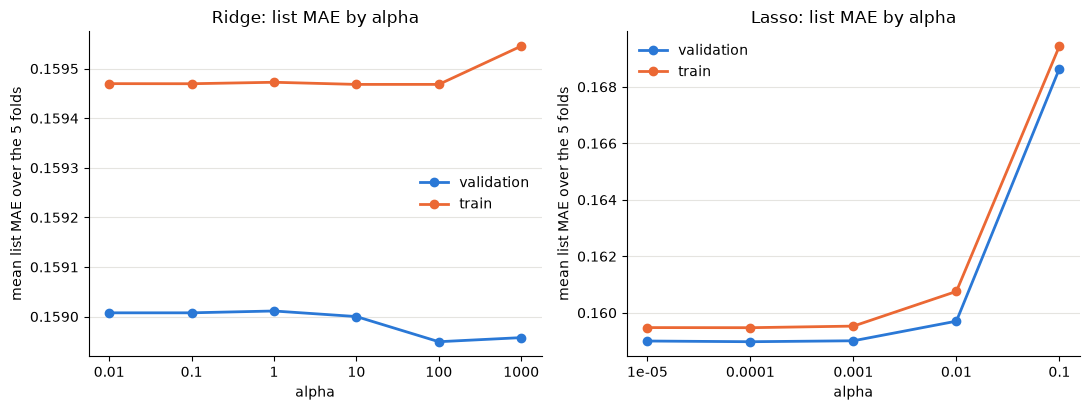

In [4]:
import matplotlib.pyplot as plt

alphas = p.load_output("baselines_alpha")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, model in zip(axes, ["ridge", "lasso"]):
    one = alphas[alphas["model"] == model]
    ax.plot(one["alpha"], one["val_list_mae"], color="#2a78d6", linewidth=2, marker="o", label="validation")
    ax.plot(one["alpha"], one["train_list_mae"], color="#eb6834", linewidth=2, marker="o", label="train")
    ax.set_xscale("log")
    ax.set_xticks(one["alpha"])
    ax.set_xticklabels([format(a, "g") for a in one["alpha"]])
    ax.minorticks_off()
    ax.set_xlabel("alpha")
    ax.set_ylabel("mean list MAE over the 5 folds")
    ax.set_title(model.capitalize() + ": list MAE by alpha")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4.3 The scores per fold

**Check: how much do the seasons differ?** The validation list MAE of every candidate in each of the 5 folds, then the training list MAE. Expected: the order constant, naive, linear models in every fold, and differences between seasons that are larger than the differences between the alphas.

**Why validation is slightly better than train.** On average over the 5 folds, ridge and lasso score a little better on the validation parts than on the training parts (about 0.0005 list MAE, see 4.2). It is not so in every fold: validation is worse in 2018/19 and 2019/20 and better in the 3 later folds. The reason: seasons differ in how predictable they are, with no trend over time, and 2 of the validation seasons are the most predictable of all 10 training seasons: by the naive rule 2022/23 comes first and 2020/21 second (see 4.7). Thin early histories do not explain it: seasons with more thin histories are not harder to predict, and the list MAE of the full histories alone moves as much from season to season (see 4.7). The cause of the differences between seasons is not known.

In [5]:
scores = p.load_output("baselines_scores_per_fold")
scores["candidate"] = scores["model"] + scores["alpha"].map(lambda a: "" if pd.isna(a) else " alpha=" + format(a, "g"))
order = list(dict.fromkeys(scores["candidate"]))           # the order of the file

for part in ["validation", "train"]:
    one = scores[scores["part"] == part]
    table = one.pivot(index="candidate", columns="val_season", values="list_mae").loc[order]
    print(part, "list MAE, 1 column per fold (named after its validation season):")
    print(table.round(4).to_string())
    print()

val = scores[scores["part"] == "validation"].pivot(index="val_season", columns="candidate", values="list_mae")
print("folds where the candidate beats the naive rule:")
for name in order[2:]:
    print(f"   {name:<20} {int((val[name] < val['naive']).sum())} of 5")

validation list MAE, 1 column per fold (named after its validation season):
val_season            1819    1920    2021    2122    2223
candidate                                                 
constant            0.3412  0.3426  0.3314  0.3368  0.3346
naive               0.1797  0.1802  0.1723  0.1748  0.1686
ridge alpha=0.01    0.1624  0.1658  0.1563  0.1565  0.1540
ridge alpha=0.1     0.1624  0.1658  0.1563  0.1565  0.1540
ridge alpha=1       0.1624  0.1658  0.1563  0.1565  0.1540
ridge alpha=10      0.1624  0.1657  0.1563  0.1565  0.1540
ridge alpha=100     0.1624  0.1655  0.1563  0.1567  0.1539
ridge alpha=1000    0.1621  0.1654  0.1566  0.1568  0.1539
lasso alpha=1e-05   0.1624  0.1658  0.1563  0.1565  0.1540
lasso alpha=0.0001  0.1625  0.1657  0.1563  0.1565  0.1539
lasso alpha=0.001   0.1625  0.1653  0.1563  0.1566  0.1543
lasso alpha=0.01    0.1633  0.1667  0.1561  0.1572  0.1552
lasso alpha=0.1     0.1741  0.1734  0.1643  0.1655  0.1660

train list MAE, 1 column per fold (nam

## 4.4 Rows with and without history

**Check: validation list MAE, separately for athletes without a previous sprint (no_history = 1) and with one (no_history = 0).** The list is made on the whole race first, then the rows are split. Expected: all models worse on the rows without history, where most inputs are empty and were filled. The naive rule should be close to the constant there, because all these rows get the same fill value and tie. The linear models can do better: they learn from the no history flag and the other inputs where newcomers usually finish. The rows without history are few (53 to 62 per fold), so their numbers move a lot.

In [6]:
history = p.load_output("baselines_history")
history["alpha"] = history["alpha"].map(lambda a: "" if pd.isna(a) else format(a, "g"))
print(history.round(4).to_string(index=False))

scores = p.load_output("baselines_scores_per_fold")
one = scores[(scores["model"] == "constant") & (scores["part"] == "validation")]
print()
print("validation rows per fold:")
print(one.assign(n_with_history=one["n_rows"] - one["n_no_history"])
      [["fold", "val_season", "n_rows", "n_no_history", "n_with_history"]].to_string(index=False))

   model  alpha  list_mae_mean  list_mae_std  list_mae_no_history_mean  list_mae_no_history_std  list_mae_with_history_mean  list_mae_with_history_std
constant                0.3373        0.0046                    0.3499                   0.0530                      0.3369                     0.0038
   naive                0.1751        0.0050                    0.3285                   0.0205                      0.1700                     0.0055
   ridge   0.01         0.1590        0.0049                    0.1885                   0.0184                      0.1580                     0.0054
   ridge    0.1         0.1590        0.0049                    0.1885                   0.0184                      0.1580                     0.0054
   ridge      1         0.1590        0.0049                    0.1885                   0.0184                      0.1580                     0.0054
   ridge     10         0.1590        0.0049                    0.1885                   0.018

## 4.5 The weights of ridge and lasso

**Check: the standardized weights of the fold 5 training fit (seasons 2013/14 to 2021/22) at every alpha.** The inputs are scaled before the last step, so every input has the same spread and the weights can be compared with each other. A weight says by how much the predicted finish percentile moves when the input goes up by 1 standard deviation and all other inputs stay the same.

* Sign: a positive weight means a higher value gives a higher predicted percentile, so a worse finish. A negative weight means a better finish.
* Size: the bigger the weight (without its sign), the more the prediction leans on this input.
* A lasso weight of exactly 0 means the input is dropped.

**What we expect.** Positive weights for the past results (finish, ski and range percentile, last place) and for the no history flag. Ridge weights almost the same for all alphas up to 100, smaller at 1000. Lasso weights that go to 0 one after the other as alpha grows.

**This is not causation.** A weight says what goes together with a result in the past races, not what makes it happen. Several inputs measure almost the same thing (for example the 2 miss features, or the finish percentile of the last 3 sprints and of the last sprint). The model shares the weight between them in the way that fits best, so a single weight can be small or even have the opposite sign of the input alone.

In [7]:
weights = p.load_output("baselines_weights")
fold5 = weights[weights["fold"] == 5]
for model in ["ridge", "lasso"]:
    one = fold5[fold5["model"] == model]
    table = one.pivot(index="feature", columns="alpha", values="weight")
    table.columns = ["alpha " + format(a, "g") for a in table.columns]
    # Sort by the size of the weight at the smallest alpha.
    table = table.reindex(table.iloc[:, 0].abs().sort_values(ascending=False).index)
    print(model.upper(), "fold 5 (training seasons 2013/14 to 2021/22)")
    print((table.round(4) + 0).to_string())
    print()

# Each input alone: its correlation with the target in the same training rows.
df = p.load_features()
train5 = p.make_folds(df)[4][1]
print("correlation of each input alone with the target, fold 5 training rows:")
print(train5[p.FEATURES].corrwith(train5[p.TARGET]).round(3).to_string())

RIDGE fold 5 (training seasons 2013/14 to 2021/22)
                        alpha 0.01  alpha 0.1  alpha 1  alpha 10  alpha 100  alpha 1000
feature                                                                                
last3_ski_pct               0.1071     0.1071   0.1071    0.1068     0.1048      0.0937
last3_finish_pct            0.0630     0.0630   0.0630    0.0631     0.0637      0.0613
last_place_any              0.0538     0.0538   0.0538    0.0538     0.0532      0.0494
no_history                  0.0424     0.0424   0.0424    0.0423     0.0419      0.0385
window_mean_misses          0.0311     0.0311   0.0311    0.0310     0.0305      0.0258
last3_miss_pct             -0.0305    -0.0305  -0.0305   -0.0305    -0.0305     -0.0269
last3_range_pct             0.0198     0.0198   0.0198    0.0198     0.0196      0.0192
last_finish_pct            -0.0102    -0.0102  -0.0102   -0.0100    -0.0083      0.0042
window_miss_dispersion     -0.0052    -0.0052  -0.0052   -0.0052    -

**Check: how many inputs does the lasso keep, and which does it drop?** For every alpha: the number of nonzero weights in each fold, the inputs dropped in the fold 5 fit, and the number of convergence warnings. A convergence warning would mean the lasso stopped after max_iter = 10000 rounds before its weights had settled. Expected: 13 inputs at the smallest alphas, fewer and fewer as alpha grows, 0 warnings.

In [8]:
linear = p.load_output("baselines_linear")
lasso = linear[linear["model"] == "lasso"]
table = lasso.pivot(index="alpha", columns="val_season", values="nonzero")
table.index = [format(a, "g") for a in table.index]
print("nonzero weights, 1 column per fold (named after its validation season):")
print(table.to_string())
print()
print("dropped in the fold 5 fit:")
for index, line in lasso[lasso["fold"] == 5].iterrows():
    dropped = line["dropped"] if isinstance(line["dropped"], str) else "none"
    print(f"   alpha {format(line['alpha'], 'g'):<7} {dropped}")
print()
print("convergence warnings, all lasso fits:", int(lasso["convergence_warnings"].sum()),
      "  other warnings, all ridge and lasso fits:", int(linear["other_warnings"].sum()))

nonzero weights, 1 column per fold (named after its validation season):
val_season  1819  1920  2021  2122  2223
1e-05         13    13    13    13    13
0.0001        13    13    13    13    13
0.001         12    13    11    11    11
0.01           7     7     7     6     6
0.1            3     3     3     3     3

dropped in the fold 5 fit:
   alpha 1e-05   none
   alpha 0.0001  none
   alpha 0.001   n_sprints_window, race_days_21d
   alpha 0.01    last3_miss_pct, last_finish_pct, n_sprints_window, window_miss_dispersion, race_days_21d, missed_prev_event, first_start_major
   alpha 0.1     last3_range_pct, last3_miss_pct, last_finish_pct, n_sprints_window, window_mean_misses, window_miss_dispersion, race_days_21d, missed_prev_event, first_start_major, no_history

convergence warnings, all lasso fits: 0   other warnings, all ridge and lasso fits: 0


## 4.6 Sanity checks

**Check: the constant model on fold 1.** Fold 1 validates on the season 2018/19. The constant is the mean of the target in its training part. Expected: a list MAE close to (n + 1) / (3n) averaged over the races (a random list, section 3.4), a list R2 close to minus 1, no rank correlation, and a top 10 hit rate near 10 divided by the number of finishers.

In [9]:
df = p.load_features()
val_season, train_part, val_part = p.make_folds(df)[0]        # fold 1
mean = train_part[p.TARGET].mean()
constant = p.predict_constant(val_part, mean)

print("validation season of fold 1:", val_season, "  rows:", len(val_part))
print("the constant (mean of the training part):", round(float(mean), 5))
for name, value in p.all_metrics(val_part, constant).items():
    print(f"{name:<9}:", round(float(value), 4))
n = val_part.groupby("race_id")["race_id"].transform("count")
print("expected list MAE, (n + 1) / (3n):", round(float(((n + 1) / (3 * n)).mean()), 4))

validation season of fold 1: 1819   rows: 1813
the constant (mean of the training part): 0.4998
list_mae : 0.3412
list_rmse: 0.4169
list_r2  : -1.0447
spearman : nan
top10    : 0.1056
expected list MAE, (n + 1) / (3n): 0.3366


**Check: the fill values differ from fold to fold.** The ridge pipeline (alpha 1) is fitted on the training part of each fold, and the medians that its fill step learned are printed for the inputs that can be empty. The fill value of the naive rule is shown too. Expected: the values are not the same in all 5 folds. This proves that the filling is fitted inside each fold, on its own training rows, and not once on all rows. The cell also checks each median against the median of the training part computed by hand.

In [10]:
df = p.load_features()
medians = {}
naive_fill = {}
by_hand_ok = True
for val_season, train_part, val_part in p.make_folds(df):
    model = p.make_ridge(1)
    model.fit(train_part[p.FEATURES], train_part[p.TARGET])
    learned = pd.Series(model.named_steps["fill"].statistics_, index=p.FEATURES)
    medians["validate " + val_season] = learned
    naive_fill["validate " + val_season] = train_part["last3_finish_pct"].median()
    by_hand_ok = by_hand_ok and np.allclose(learned, train_part[p.FEATURES].median())

table = pd.DataFrame(medians)
can_be_empty = df[p.FEATURES].isna().any()              # inputs with at least 1 empty cell
print(table[can_be_empty].round(4))
print()
print("fill value of the naive rule:", {k: round(v, 4) for k, v in naive_fill.items()})
print("inputs whose median is not the same in all 5 folds:", int((table[can_be_empty].nunique(axis=1) > 1).sum()),
      "of", int(can_be_empty.sum()), "that can be empty")
print("every median equals the median of its training part:", by_hand_ok)

                    validate 1819  validate 1920  validate 2021  validate 2122  validate 2223
last3_finish_pct           0.4872         0.4894         0.4880         0.4880         0.4899
last3_ski_pct              0.4865         0.4877         0.4882         0.4885         0.4910
last3_range_pct            0.4976         0.4983         0.4982         0.4964         0.4986
last3_miss_pct             0.4927         0.4934         0.4937         0.4922         0.4930
last_finish_pct            0.4900         0.4900         0.4902         0.4896         0.4900
last_place_any            46.0000        46.0000        47.0000        47.0000        47.0000
window_mean_misses         2.0000         2.0000         2.0000         2.0000         2.0000

fill value of the naive rule: {'validate 1819': np.float64(0.4872), 'validate 1920': np.float64(0.4894), 'validate 2021': np.float64(0.488), 'validate 2122': np.float64(0.488), 'validate 2223': np.float64(0.4899)}
inputs whose median is not the sa

**Check: no row from 2023/24 or later is loaded.** Every function of step 4 gets its rows from `p.load_features()`, which drops the test seasons before it gives the table back. Expected: the latest season is 2022/23, 0 rows of a test season, only the 5 validation seasons in the saved score table, and validation rows that add up to the rows of these 5 seasons.

In [11]:
df = p.load_features()
print("seasons in the table      :", sorted(df["season"].unique()))
print("latest start date         :", df["start"].max()[:10])
print("rows of a test season     :", int(df["season"].isin(p.TEST_SEASONS).sum()))

folds = p.make_folds(df)
used = pd.concat([train_part for val_season, train_part, val_part in folds] +
                 [val_part for val_season, train_part, val_part in folds])
print("seasons used by the folds :", sorted(used["season"].unique()))

scores = p.load_output("baselines_scores_per_fold")
print("validation seasons in the saved score table:", sorted(scores["val_season"].unique()))
one = scores[(scores["model"] == "constant") & (scores["part"] == "validation")]
print("validation rows in the score table:", int(one["n_rows"].sum()),
      "  rows of these 5 seasons in the feature table:", int(df["season"].isin(p.VALIDATION_SEASONS).sum()))

seasons in the table      : ['1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']
latest start date         : 2023-03-18
rows of a test season     : 0
seasons used by the folds : ['1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']
validation seasons in the saved score table: ['1819', '1920', '2021', '2122', '2223']
validation rows in the score table: 9117   rows of these 5 seasons in the feature table: 9117


**Check: the saved tables are up to date.** The cell runs the whole of step 4 again (about 20 seconds) and compares with the files in `outputs/`. Expected: 0 different numbers. Numbers count as the same when they are equal to 12 decimals, because saving a number in a file and reading it back can move the last digit.

In [12]:
scores, weights, linear = p.score_baselines()          # the whole of step 4, again
for name, now in [("baselines_scores_per_fold", scores), ("baselines_weights", weights), ("baselines_linear", linear)]:
    saved = p.load_output(name)
    columns = now.select_dtypes("number").columns
    a = now[columns].to_numpy(dtype=float)
    b = saved[columns].to_numpy(dtype=float)
    both_empty = np.isnan(a) & np.isnan(b)
    difference = np.where(both_empty, 0, np.abs(a - b))
    print(f"{name:<26} numbers: {a.size:>5}   different by more than 0.000000000001: {int((difference > 1e-12).sum())}")

  fold 1 of 5 done


  fold 2 of 5 done


  fold 3 of 5 done


  fold 4 of 5 done


  fold 5 of 5 done
baselines_scores_per_fold  numbers:  1430   different by more than 0.000000000001: 0
baselines_weights          numbers:  2145   different by more than 0.000000000001: 0
baselines_linear           numbers:   275   different by more than 0.000000000001: 0


## 4.7 Why are later seasons easier to predict?

**Added on 16 Nov, redone on 18 Nov with the list metric.** The guess was: the data starts in 2012/13, so in the early seasons many athletes have a thin history (no past sprint, or fewer than 3), and a thin history is harder to predict from.

**Check: per training season, the list MAE of the naive rule next to how thin the histories are.** For each season 2013/14 to 2022/23: the number of rows, the list MAE of the naive rule, the share of rows with no_history = 1, and the share of rows with fewer than 3 past sprints (0, 1 or 2 valid sprints before, over the whole history). The naive rule fills empty values with the median of all 10 training seasons; it learns nothing else, so its score in a season does not depend on any other season. The list is made on whole races, then the rows are split into full histories (3 past sprints or more) and thin ones. Expected if the guess is right: the early seasons have more thin histories and a higher list MAE, and the list MAE of the full histories is about the same in every season.

In [13]:
fin = p.load_fin()
train = fin[fin["season"].isin(p.TRAIN_SEASONS)].copy()
fill = train["last3_finish_pct"].median()
train["error"] = np.abs(p.list_percentile(train, p.predict_naive(train, fill)) - train[p.TARGET].to_numpy())
train["thin"] = train["n_before_all"] < 3              # fewer than 3 past sprints, whole history

table = pd.DataFrame({
    "rows": train.groupby("season").size(),
    "naive_list_mae": train.groupby("season")["error"].mean(),
    "share_no_history": train.groupby("season")["no_history"].mean(),
    "share_fewer_than_3": train.groupby("season")["thin"].mean(),
    "naive_list_mae_full_history": train[~train["thin"]].groupby("season")["error"].mean(),
    "naive_list_mae_thin_history": train[train["thin"]].groupby("season")["error"].mean(),
})
print(table.round(4))
print()
print("correlation over the 10 seasons between the naive list MAE and")
print("   the share of no_history rows    :", round(table["naive_list_mae"].corr(table["share_no_history"]), 2))
print("   the share with fewer than 3 past:", round(table["naive_list_mae"].corr(table["share_fewer_than_3"]), 2))
print()
print("the 10 seasons from the most to the least predictable (naive list MAE):")
print(table["naive_list_mae"].sort_values().round(4).to_string())
print("mean of the 5 validation seasons:", round(table.loc[p.VALIDATION_SEASONS, "naive_list_mae"].mean(), 4),
      "  mean of the 5 seasons before:", round(table.drop(p.VALIDATION_SEASONS)["naive_list_mae"].mean(), 4))

        rows  naive_list_mae  share_no_history  share_fewer_than_3  naive_list_mae_full_history  naive_list_mae_thin_history
season                                                                                                                      
1314    1842          0.1736            0.0423              0.1156                       0.1694                       0.2060
1415    1928          0.1747            0.0420              0.1260                       0.1687                       0.2163
1516    1730          0.1796            0.0243              0.0740                       0.1774                       0.2073
1617    1815          0.1728            0.0292              0.0722                       0.1694                       0.2170
1718    1751          0.1802            0.0183              0.0571                       0.1781                       0.2146
1819    1813          0.1795            0.0342              0.0877                       0.1731                       0.2455


## 4.8 How strongly does each measure repeat from 1 sprint to the next?

**Check: the correlation between the value in 1 sprint and the value in the next sprint of the same athlete.** We take the valid finishes of the training seasons, put the sprints of each athlete in time order, and pair every sprint with the next one (a pair can go over a summer break). For finish percentile, ski percentile, range percentile, misses and miss percentile (the measure behind feature 4): the correlation over all pairs, and the number of pairs. A correlation of 1 would mean the next value is known exactly, 0 would mean the last value says nothing. Expected: ski percentile the highest, the 2 miss measures the lowest, finish percentile in between, because the finish mixes skiing and shooting.

In [14]:
fin = p.load_fin()
fin = fin[fin["season"].isin(p.TRAIN_SEASONS)].sort_values(["IBUId", "start"])

lines = []
for name, col in [("finish percentile", "finish_pct"), ("ski percentile", "ski_pct"),
                  ("range percentile", "range_pct"), ("misses", "misses"), ("miss percentile", "miss_pct")]:
    this_sprint = fin[col]
    next_sprint = fin.groupby("IBUId")[col].shift(-1)       # the value in the athlete's next sprint
    both = this_sprint.notna() & next_sprint.notna()         # pairs where both values exist
    lines.append({"measure": name,
                  "correlation": round(this_sprint[both].corr(next_sprint[both]), 3),
                  "pairs": int(both.sum())})
print(pd.DataFrame(lines).to_string(index=False))
print()
print("athletes with at least 1 pair:", int((fin.groupby("IBUId").size() > 1).sum()))

          measure  correlation  pairs
finish percentile        0.632  17301
   ski percentile        0.830  17295
 range percentile        0.582  17293
           misses        0.171  17301
  miss percentile        0.178  17301

athletes with at least 1 pair: 779


## 4.9 Ridge predictions outside the range 0 to 1

The finish percentile lies between 0 and 1. The ridge model is a straight line rule and knows nothing about these limits, so it can predict a value below 0 or above 1. For the list metric this does no harm: only the order of the predictions inside a race counts, and a value outside the range keeps its place in the order.

**Check: how many validation predictions are outside the range.** For each of the 5 folds the ridge pipeline at alpha 10 (the alpha of this check since 16 Nov, not a choice) is fitted on the training part and predicts the validation part. Shown per fold and in total: the number of predictions below 0, the number above 1, the lowest and the highest value. Expected: few, and only just outside the range. The last lines compare the list MAE of the predictions as they are and cut to the range: they can only differ if cutting makes 2 predictions equal.

In [15]:
df = p.load_features()
lines = []
all_pred = []
all_rows = []
for val_season, train_part, val_part in p.make_folds(df):
    model = p.make_ridge(10)
    model.fit(train_part[p.FEATURES], train_part[p.TARGET])     # training part of the fold only
    pred = model.predict(val_part[p.FEATURES])
    lines.append({"val_season": val_season, "rows": len(pred),
                  "below_0": int((pred < 0).sum()), "above_1": int((pred > 1).sum()),
                  "lowest": pred.min(), "highest": pred.max()})
    all_pred.append(pred)
    all_rows.append(val_part)

print(pd.DataFrame(lines).round(3).to_string(index=False))
pred = np.concatenate(all_pred)
rows = pd.concat(all_rows)
print()
print("all validation rows  :", len(pred))
print("outside the range    :", int(((pred < 0) | (pred > 1)).sum()))
print("list MAE as predicted:", round(float(p.list_mae(rows, pred)), 5))
print("list MAE, cut to 0..1:", round(float(p.list_mae(rows, np.clip(pred, 0, 1))), 5))

val_season  rows  below_0  above_1  lowest  highest
      1819  1813        0        0   0.063    0.955
      1920  1655        0        3   0.059    1.120
      2021  2060        0        1   0.040    1.034
      2122  2017        0        1   0.052    1.048
      2223  1572        0        1   0.067    1.004

all validation rows  : 9117
outside the range    : 6
list MAE as predicted: 0.15889
list MAE, cut to 0..1: 0.15889


# Section 5: Model families and the final choice

Rewritten on 18 Nov: 4 model families on 2 input sets, scored with the list metric (section 3.4), on the new features (section 2). All rules below were written down before any step 5 result was seen and are applied mechanically.

**Setup, same as section 4.** Rows: training seasons 2013/14 to 2022/23. Folds: the 5 walk forward season folds. Target: finish percentile. The test seasons are not used. Every number a model learns comes from the training part of the fold. Every standard deviation is the sample one (ddof = 1). SE means standard error: the standard deviation of the 5 fold values divided by the square root of 5. The seed is 42 everywhere.

**The 2 input sets.**

* FULL, with load: the 13 inputs of section 4.
* NO_LOAD, without load: 10 inputs, FULL without `race_days_21d`, `missed_prev_event` and `first_start_major` (the constant `LOAD_FEATURES` in `pipeline.py`).

**The 4 families, each on both input sets.**

1. Ridge: median fill, StandardScaler, Ridge. Alpha 0.01, 0.1, 1, 10, 100, 1000.
2. Lasso: median fill, StandardScaler, Lasso (max_iter = 10000). Alpha 0.00001, 0.0001, 0.001, 0.01, 0.1.
3. Random forest: median fill, RandomForestRegressor with 300 trees, max_features = 1/3, random_state = 42. No scaler. Depth 2, 4, 6, 8, 12, 16 and None (no limit). Refinement round, once, for each input set: the 2 depths halfway between the best depth and its neighbours in the grid are added.
4. Gradient boosting: HistGradientBoostingRegressor with at most 2000 trees, early stopping, random_state = 42. No fill (it handles empty values itself), no scaler. Learning rate 0.02, 0.05, 0.1, 0.2 times depth 3, 4, 6 (the grid of L12). Early stopping keeps 10 % of the training rows apart and stops adding trees when they no longer help there; the number of trees used is recorded in each fold.

**The selection rule (one standard error rule).**

1. Best = the lowest mean validation list MAE over all candidates of all families and both input sets.
2. SE = standard deviation of the 5 fold scores of the best candidate divided by the square root of 5. Threshold = best + SE.
3. Eligible = every candidate with a mean validation list MAE at or below the threshold.
4. Among the eligible, the simplest wins, in this order: (a) fewer inputs, where a lasso counts the largest number of nonzero weights over the 5 folds; (b) linear before trees, at equal inputs ridge before lasso, forest before boosting; (c) inside a family the larger alpha (ridge, lasso), the smaller depth (forest), the smaller depth and then fewer trees used, mean over the folds (boosting).
5. Grid edge: if the chosen candidate sits at the edge of its grid, that grid is extended by 2 steps beyond the edge, once, and the selection is repeated.

**Where the numbers come from.** The command `python pipeline.py models` (about 5 minutes) does all of this and saves 11 tables in `outputs/`, all with a name that starts with `models_`. The cells below show these tables through `p.load_output`. In the tables, the depth None is written as `inf` (infinity), so that it sorts as the deepest. The choice is written into `FINAL_FAMILY`, `FINAL_INPUTS` and `FINAL_VALUE` in `pipeline.py`. Step 6 is locked (`TEST_UNLOCKED = False`): the test seasons cannot be read until the lock is opened by hand.

## 5.1 All candidates in 1 table

**Check: every candidate, sorted by mean validation list MAE, best first.** For each: its raw rank, the number of inputs that the simplicity rule counts, the mean training list MAE, then on the validation parts the mean list MAE, its standard deviation and SE, the means of rank correlation and top 10 hit rate, and the gap validation minus train. The last columns say if the candidate is eligible and which one is the final model. Expected: the middle of every grid close together, the extreme settings (depth 2, alpha 0.1 for lasso, no depth limit) clearly worse. Deep forests and boosting fit the training rows much better than the validation rows; ridge and lasso about the same on both.

In [2]:
table = p.load_output("models_candidates")
print("candidates:", len(table))
show = ["raw_rank", "name", "simplicity_inputs", "train_list_mae_mean", "val_list_mae_mean", "val_list_mae_std",
        "val_list_mae_se", "val_spearman_mean", "val_top10_mean", "gap_val_minus_train", "eligible", "final_model"]
print(table[show].round(5).to_string(index=False))

candidates: 64
 raw_rank                             name  simplicity_inputs  train_list_mae_mean  val_list_mae_mean  val_list_mae_std  val_list_mae_se  val_spearman_mean  val_top10_mean  gap_val_minus_train  eligible  final_model
        1 boosting NO_LOAD lr=0.02 depth=3               10.0              0.15548            0.15856           0.00443          0.00198            0.74436         0.53603              0.00308      True        False
        2    boosting FULL lr=0.05 depth=4               13.0              0.15258            0.15858           0.00466          0.00208            0.74489         0.53942              0.00600      True        False
        3    boosting FULL lr=0.02 depth=3               13.0              0.15532            0.15858           0.00440          0.00197            0.74463         0.53553              0.00326      True        False
        4 boosting NO_LOAD lr=0.05 depth=4               10.0              0.15284            0.15866           0.00467  

## 5.2 The forest depth curve and the boosting grid

**Check: mean list MAE of the forest by depth, on train and on validation, for both input sets.** This look chooses nothing. Expected: the training list MAE falls with every step of depth. The validation list MAE falls at first, reaches a low point and then rises: beyond that depth the trees learn noise. The 2 depths of the refinement round are in the table too.

In [3]:
curve = p.load_output("models_depth_curve")
wide = curve.pivot(index="value", columns="inputs", values=["train_list_mae_mean", "val_list_mae_mean"])
wide.index = [("None" if v == np.inf else str(int(v))) for v in wide.index]
wide.index.name = "depth"
print(wide.round(5))
print()
for inputs in ["FULL", "NO_LOAD"]:
    one = curve[curve["inputs"] == inputs]
    best = one.loc[one["val_list_mae_mean"].idxmin()]
    print(inputs, ": lowest validation list MAE at depth",
          "None" if best["value"] == np.inf else int(best["value"]), "=", round(best["val_list_mae_mean"], 5))

       train_list_mae_mean          val_list_mae_mean         
inputs                FULL  NO_LOAD              FULL  NO_LOAD
depth                                                         
2                  0.16576  0.16598           0.16522  0.16545
4                  0.16060  0.16083           0.16101  0.16095
6                  0.15523  0.15545           0.15932  0.15951
7                  0.15119  0.15151           0.15911  0.15915
8                  0.14576  0.14613           0.15903  0.15887
10                 0.13052  0.13126           0.15892  0.15898
12                 0.11127  0.11225           0.15907  0.15962
16                 0.07642  0.07708           0.15983  0.16046
None               0.05122  0.05188           0.16063  0.16057

FULL : lowest validation list MAE at depth 10 = 0.15892
NO_LOAD : lowest validation list MAE at depth 8 = 0.15887


**The same numbers as a picture.** Left: validation. Right: train. The 2 panels have different list MAE axes, because the training list MAE of a deep forest is far below everything else. The depths are placed at equal distance, they are not to scale.

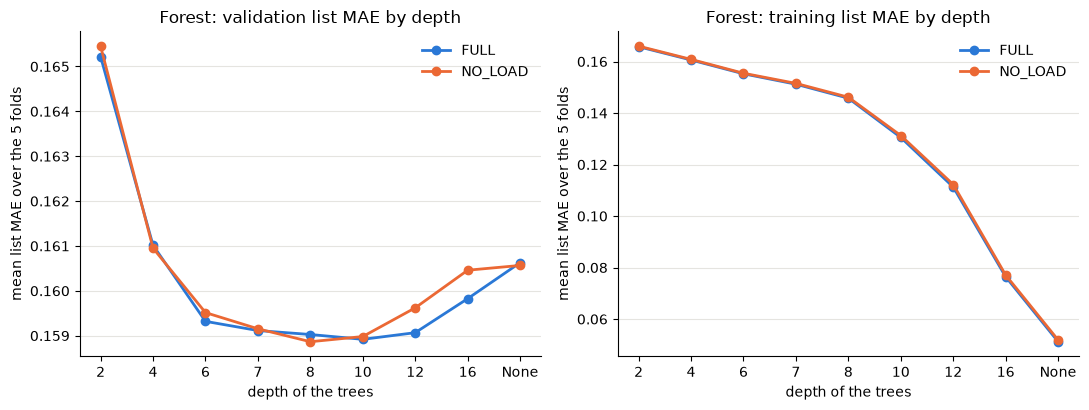

In [4]:
import matplotlib.pyplot as plt

curve = p.load_output("models_depth_curve")
colors = {"FULL": "#2a78d6", "NO_LOAD": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, column, title in [(axes[0], "val_list_mae_mean", "Forest: validation list MAE by depth"),
                          (axes[1], "train_list_mae_mean", "Forest: training list MAE by depth")]:
    for inputs in ["FULL", "NO_LOAD"]:
        one = curve[curve["inputs"] == inputs].sort_values("value")
        labels = [("None" if v == np.inf else str(int(v))) for v in one["value"]]
        ax.plot(range(len(one)), one[column], color=colors[inputs], linewidth=2, marker="o", label=inputs)
        ax.set_xticks(range(len(one)))
        ax.set_xticklabels(labels)
    ax.set_xlabel("depth of the trees")
    ax.set_ylabel("mean list MAE over the 5 folds")
    ax.set_title(title)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Check: the boosting grid and the trees used.** First the mean validation list MAE for every learning rate and depth, for both input sets. Then the number of trees that early stopping kept in each fold. Expected: a smaller learning rate needs more trees (each tree corrects less), a deeper tree needs fewer. No candidate should use all 2000 trees: that would mean early stopping never stopped.

In [5]:
table = p.load_output("models_candidates")
boost = table[table["family"] == "boosting"]
for inputs in ["FULL", "NO_LOAD"]:
    one = boost[boost["inputs"] == inputs]
    grid = one.pivot(index="learning_rate", columns="value", values="val_list_mae_mean")
    grid.columns = ["depth " + str(int(d)) for d in grid.columns]
    print(inputs, "validation list MAE, learning rate x depth:")
    print(grid.round(5).to_string())
    print()

trees = p.load_output("models_boosting_trees")
print("trees used per fold (named after its validation season), and the mean:")
print(trees.round(1).to_string(index=False))
print()
seasons = [c for c in trees.columns if c not in ["name", "mean"]]
print("smallest and largest number of trees used:", int(trees[seasons].min().min()), "and", int(trees[seasons].max().max()),
      "  fits that used all", p.BOOST_MAX_ITER, "trees:", int((trees[seasons] == p.BOOST_MAX_ITER).sum().sum()))

FULL validation list MAE, learning rate x depth:
               depth 3  depth 4  depth 6
learning_rate                           
0.02           0.15858  0.15879  0.15870
0.05           0.15867  0.15858  0.15875
0.10           0.15896  0.15908  0.15928
0.20           0.15925  0.15914  0.15944

NO_LOAD validation list MAE, learning rate x depth:
               depth 3  depth 4  depth 6
learning_rate                           
0.02           0.15856  0.15869  0.15895
0.05           0.15869  0.15866  0.15877
0.10           0.15898  0.15872  0.15934
0.20           0.15930  0.15962  0.16013

trees used per fold (named after its validation season), and the mean:
                            name  1819  1920  2021  2122  2223  mean
   boosting FULL lr=0.02 depth=3 381.0 339.0 303.0 384.0 409.0 363.2
   boosting FULL lr=0.02 depth=4 274.0 224.0 232.0 321.0 428.0 295.8
   boosting FULL lr=0.02 depth=6 166.0 193.0 246.0 193.0 165.0 192.6
   boosting FULL lr=0.05 depth=3 160.0 139.0 216.0 154.0 2

## 5.3 The selection, step by step

**Check: the one standard error rule, redone here from the saved fold scores.** The cell builds the candidate table again from the score of every candidate in every fold and walks through the rule: best, SE (also by hand from its 5 fold scores), threshold, eligible, the eligible sorted from the simplest, the grid edge, the choice and its raw rank. Expected: the same final model as in the saved table `models_selection` and as written in `pipeline.py`.

In [6]:
scores = p.load_output("models_scores_per_fold")
table = p.candidate_table(scores)
choice = p.one_se_rule(table)
folds = p.fold_values(scores, choice["best"])

print("1. candidates in the pool      :", len(table))
print("   best (lowest mean)          :", choice["best"], " mean:", round(choice["best_mean"], 5))
print("2. its 5 fold list MAEs        :", folds.round(5))
print("   SE by hand = std / sqrt(5)  :", round(folds.std(ddof=1) / np.sqrt(5), 5), "  from the function:", round(choice["se"], 5))
print("   threshold = best + SE       :", round(choice["threshold"], 5))
eligible = table[table["name"].isin(choice["eligible"])]
print("3. eligible candidates         :", len(eligible), "of", len(table))
print("4. the eligible, simplest first (the first line is chosen):")
order = p.simplest_first(eligible)
order["family_order"] = order["family"].map(p.FAMILY_ORDER)
print(order[["name", "simplicity_inputs", "family_order", "trees_used_mean", "val_list_mae_mean"]]
      .head(15).round(5).to_string(index=False))
print("   ... and", len(order) - 15, "more")
line = table[table["name"] == choice["chosen"]].iloc[0]
print("5. grid edge of the choice     :", p.grid_edge(line), " (None = not at an edge)")
print()
print("THE CHOICE                     :", choice["chosen"])
print("its mean validation list MAE   :", round(choice["chosen_mean"], 5), "  raw rank:", choice["chosen_raw_rank"], "of", len(table))
print("in the saved table             :", p.load_output("models_selection")["final_model"].iloc[0])
print("written in pipeline.py         :", p.candidate_name(p.FINAL_FAMILY, p.FINAL_INPUTS, p.FINAL_VALUE))

1. candidates in the pool      : 64
   best (lowest mean)          : boosting NO_LOAD lr=0.02 depth=3  mean: 0.15856
2. its 5 fold list MAEs        : [0.16255 0.16388 0.15613 0.1566  0.15362]
   SE by hand = std / sqrt(5)  : 0.00198   from the function: 0.00198
   threshold = best + SE       : 0.16054
3. eligible candidates         : 56 of 64
4. the eligible, simplest first (the first line is chosen):
                      name  simplicity_inputs  family_order  trees_used_mean  val_list_mae_mean
  lasso NO_LOAD alpha=0.01                7.0             2              NaN            0.15969
     lasso FULL alpha=0.01                7.0             2              NaN            0.15970
  ridge NO_LOAD alpha=1000               10.0             1              NaN            0.15918
   ridge NO_LOAD alpha=100               10.0             1              NaN            0.15898
    ridge NO_LOAD alpha=10               10.0             1              NaN            0.15896
     ridge NO_LOAD 

**A tie that the rule did not foresee.** The 2 simplest eligible candidates, lasso NO_LOAD and lasso FULL at alpha 0.01, are equal on every key of step 4 of the rule: the same largest number of nonzero weights (7), the same family, the same alpha. The code then keeps the order of the candidate table, which is sorted by mean validation list MAE, so the NO_LOAD candidate comes first (lower by about 0.00002). NO_LOAD also offers fewer inputs (10 against 13), so the other natural way to break the tie gives the same answer. The cell shows the 2 candidates side by side.

In [7]:
scores = p.load_output("models_scores_per_fold")
names = ["lasso NO_LOAD alpha=0.01", "lasso FULL alpha=0.01"]
val = scores[(scores["part"] == "validation") & scores["name"].isin(names)]
print("nonzero weights per fold:")
print(val.pivot(index="val_season", columns="name", values="nonzero")[names].to_string())
print()
print("validation list MAE per fold:")
print(val.pivot(index="val_season", columns="name", values="list_mae")[names].round(5).to_string())
table = p.load_output("models_candidates").set_index("name")
print()
print("mean validation list MAE:", {name: round(table.loc[name, "val_list_mae_mean"], 6) for name in names})

nonzero weights per fold:
name        lasso NO_LOAD alpha=0.01  lasso FULL alpha=0.01
val_season                                                 
1819                             6.0                    7.0
1920                             6.0                    7.0
2021                             7.0                    7.0
2122                             6.0                    6.0
2223                             6.0                    6.0

validation list MAE per fold:
name        lasso NO_LOAD alpha=0.01  lasso FULL alpha=0.01
val_season                                                 
1819                         0.16328                0.16329
1920                         0.16661                0.16668
2021                         0.15612                0.15612
2122                         0.15720                0.15720
2223                         0.15522                0.15522

mean validation list MAE: {'lasso NO_LOAD alpha=0.01': np.float64(0.159687), 'lasso FULL alpha=0.01': 

**Check: the best candidate of each family and input set.** This does not change the choice. For each of the 8 groups: the candidate with the lowest mean validation list MAE, its mean and standard deviation, rank correlation, top 10 hit rate, the training list MAE and the gap validation minus train. Expected: the 4 families close together; a large positive gap for the forest (deep trees learn the training rows), a smaller one for boosting, about 0 for ridge and lasso.

In [8]:
groups = p.load_output("models_groups")
print(groups[["family", "inputs", "best", "val_list_mae_mean", "val_list_mae_std", "val_spearman_mean",
              "val_top10_mean", "train_list_mae_mean", "gap_val_minus_train"]].round(5).to_string(index=False))

  family  inputs                             best  val_list_mae_mean  val_list_mae_std  val_spearman_mean  val_top10_mean  train_list_mae_mean  gap_val_minus_train
   ridge    FULL             ridge FULL alpha=100            0.15895           0.00480            0.74335         0.53386              0.15947             -0.00052
   ridge NO_LOAD           ridge NO_LOAD alpha=10            0.15896           0.00493            0.74362         0.53386              0.15953             -0.00057
   lasso    FULL          lasso FULL alpha=0.0001            0.15898           0.00491            0.74340         0.53386              0.15947             -0.00050
   lasso NO_LOAD        lasso NO_LOAD alpha=1e-05            0.15897           0.00492            0.74358         0.53386              0.15954             -0.00056
  forest    FULL             forest FULL depth=10            0.15892           0.00439            0.74409         0.52817              0.13052              0.02840
  forest NO_LOAD

## 5.4 With and without the load features

The load hypothesis: how much and how recently an athlete raced (the 3 load features) helps to predict the sprint.

**Check: for each family, the best FULL candidate against the best NO_LOAD candidate.** Shown: the 2 mean validation list MAEs, the difference with load minus without load in each fold, the mean difference and the SE of the difference (sample standard deviation of the 5 fold differences divided by the square root of 5). A value below 0 means the load features help. Expected if they help: below 0 in most folds, and a mean difference clearly larger than its SE. If the mean difference is smaller than its SE, the data cannot tell the 2 input sets apart.

In [9]:
comparisons = p.load_output("models_comparisons")
for index, line in comparisons.iterrows():
    folds = [line["diff_fold_" + str(number)] for number in range(1, 6)]
    print(line["comparison"])
    print("   with load   :", line["a"], " mean:", round(line["a_mean"], 5))
    print("   without load:", line["b"], " mean:", round(line["b_mean"], 5))
    print("   difference in each fold:", [round(value, 5) for value in folds],
          "  folds where the load helps:", sum(value < 0 for value in folds), "of 5")
    print("   mean difference:", round(line["diff_mean"], 5), "  SE:", round(line["diff_se"], 5),
          "  mean / SE:", round(line["diff_mean"] / line["diff_se"], 2))
    print()

load, ridge: with minus without
   with load   : ridge FULL alpha=100  mean: 0.15895
   without load: ridge NO_LOAD alpha=10  mean: 0.15896
   difference in each fold: [-6e-05, -0.00021, -0.0001, 0.00016, 0.00015]   folds where the load helps: 3 of 5
   mean difference: -1e-05   SE: 7e-05   mean / SE: -0.15

load, lasso: with minus without
   with load   : lasso FULL alpha=0.0001  mean: 0.15898
   without load: lasso NO_LOAD alpha=1e-05  mean: 0.15897
   difference in each fold: [-3e-05, 3e-05, -7e-05, -3e-05, 0.00012]   folds where the load helps: 3 of 5
   mean difference: 0.0   SE: 3e-05   mean / SE: 0.05

load, forest: with minus without
   with load   : forest FULL depth=10  mean: 0.15892
   without load: forest NO_LOAD depth=8  mean: 0.15887
   difference in each fold: [-0.00045, -0.00069, 0.00087, 0.0004, 0.00013]   folds where the load helps: 2 of 5
   mean difference: 5e-05   SE: 0.00028   mean / SE: 0.19

load, boosting: with minus without
   with load   : boosting FULL lr=0.

## 5.5 The families per fold

**Check: the best candidate of each family (over both input sets), and the final model, in each fold.** Shown: the validation list MAE per fold, then the difference of each best candidate to the final model in each fold. Expected: the same season pattern for all (section 4.3), and differences between the families that are small next to the differences between the seasons.

In [10]:
scores = p.load_output("models_scores_per_fold")
table = p.load_output("models_candidates")
final = table[table["final_model"]]["name"].iloc[0]
names = [p.best_name(table, family=family) for family in p.FAMILY_ORDER] + [final]
val = scores[(scores["part"] == "validation") & scores["name"].isin(names)]
wide = val.pivot(index="val_season", columns="name", values="list_mae")[names]
print("validation list MAE per fold:")
print(wide.round(5).to_string())
print()
print("difference to the final model (" + final + "), per fold:")
print(wide[names[:-1]].sub(wide[final], axis=0).round(5).to_string())
print()
print("spread between the seasons (largest minus smallest fold), final model:", round(wide[final].max() - wide[final].min(), 5))

validation list MAE per fold:
name        ridge FULL alpha=100  lasso NO_LOAD alpha=1e-05  forest NO_LOAD depth=8  boosting NO_LOAD lr=0.02 depth=3  lasso NO_LOAD alpha=0.01
val_season                                                                                                                                     
1819                     0.16241                    0.16252                 0.16275                           0.16255                   0.16328
1920                     0.16545                    0.16565                 0.16509                           0.16388                   0.16661
2021                     0.15633                    0.15639                 0.15615                           0.15613                   0.15612
2122                     0.15670                    0.15658                 0.15698                           0.15660                   0.15720
2223                     0.15385                    0.15374                 0.15335                       

## 5.6 Rows with and without history

**Check: validation list MAE of the best candidate of each family and input set, separately for athletes without a previous sprint (no_history = 1) and with one.** The list is made on the whole race first, then the rows are split. Expected: every model clearly worse on the rows without history. Trees could do better there than linear models, because a tree can make a separate rule for newcomers. The no history groups are small (53 to 62 rows per fold).

In [11]:
history = p.load_output("models_history")
print(history.round(5).to_string(index=False))
table = p.load_output("models_candidates")
final = table[table["final_model"]].iloc[0]
print()
print("final model", final["name"], ": without history", round(final["val_list_mae_no_history_mean"], 5),
      "  with history", round(final["val_list_mae_with_history_mean"], 5))

  family  inputs                             best  val_list_mae_mean  val_list_mae_no_history_mean  val_list_mae_with_history_mean
   ridge    FULL             ridge FULL alpha=100            0.15895                       0.18817                         0.15795
   ridge NO_LOAD           ridge NO_LOAD alpha=10            0.15896                       0.18786                         0.15796
   lasso    FULL          lasso FULL alpha=0.0001            0.15898                       0.18840                         0.15797
   lasso NO_LOAD        lasso NO_LOAD alpha=1e-05            0.15897                       0.18789                         0.15798
  forest    FULL             forest FULL depth=10            0.15892                       0.18019                         0.15820
  forest NO_LOAD           forest NO_LOAD depth=8            0.15887                       0.18394                         0.15801
boosting    FULL    boosting FULL lr=0.05 depth=4            0.15858               

## 5.7 The learning curve

**Check: does more data still help?** For the final model and for the best candidate of each other family: the model is trained on 20, 40, 60, 80 and 100 % of the training races of each fold (whole races, because a result list needs whole races; a random subset with the seed 42) and scored on the same validation part. Shown: the mean training list MAE and the mean validation list MAE over the 5 folds. This look chooses nothing. Expected: the validation list MAE falls when the share grows and flattens out. For the trees the training list MAE rises with more data (a tree can follow few rows more closely than many), so the gap between the 2 lines shrinks. For a strongly pulled linear model both lines can stay close.

In [12]:
curve = p.load_output("models_learning_curve")
for name in curve["name"].unique():
    one = curve[curve["name"] == name]
    print(one["role"].iloc[0], ":", name)
    print(one[["share", "n_train_races", "n_train_rows", "train_list_mae", "val_list_mae"]].round(5).to_string(index=False))
    print("   change of the validation list MAE from 80 % to 100 %:",
          round(one["val_list_mae"].iloc[-1] - one["val_list_mae"].iloc[-2], 5),
          "   from 20 % to 100 %:", round(one["val_list_mae"].iloc[-1] - one["val_list_mae"].iloc[0], 5))
    print()

best of another family : boosting NO_LOAD lr=0.02 depth=3
 share  n_train_races  n_train_rows  train_list_mae  val_list_mae
   0.2           26.2        2573.0         0.14741       0.16115
   0.4           52.0        5113.6         0.15168       0.16046
   0.6           78.0        7656.4         0.15278       0.15948
   0.8          103.8       10198.8         0.15471       0.15951
   1.0          130.0       12736.8         0.15548       0.15856
   change of the validation list MAE from 80 % to 100 %: -0.00096    from 20 % to 100 %: -0.0026

best of another family : forest NO_LOAD depth=8
 share  n_train_races  n_train_rows  train_list_mae  val_list_mae
   0.2           26.2        2573.0         0.12044       0.16111
   0.4           52.0        5113.6         0.13294       0.15993
   0.6           78.0        7656.4         0.13912       0.15959
   0.8          103.8       10198.8         0.14343       0.15914
   1.0          130.0       12736.8         0.14613       0.15887
   c

**The same numbers as a picture.** 1 panel per model, each with its own list MAE axis.

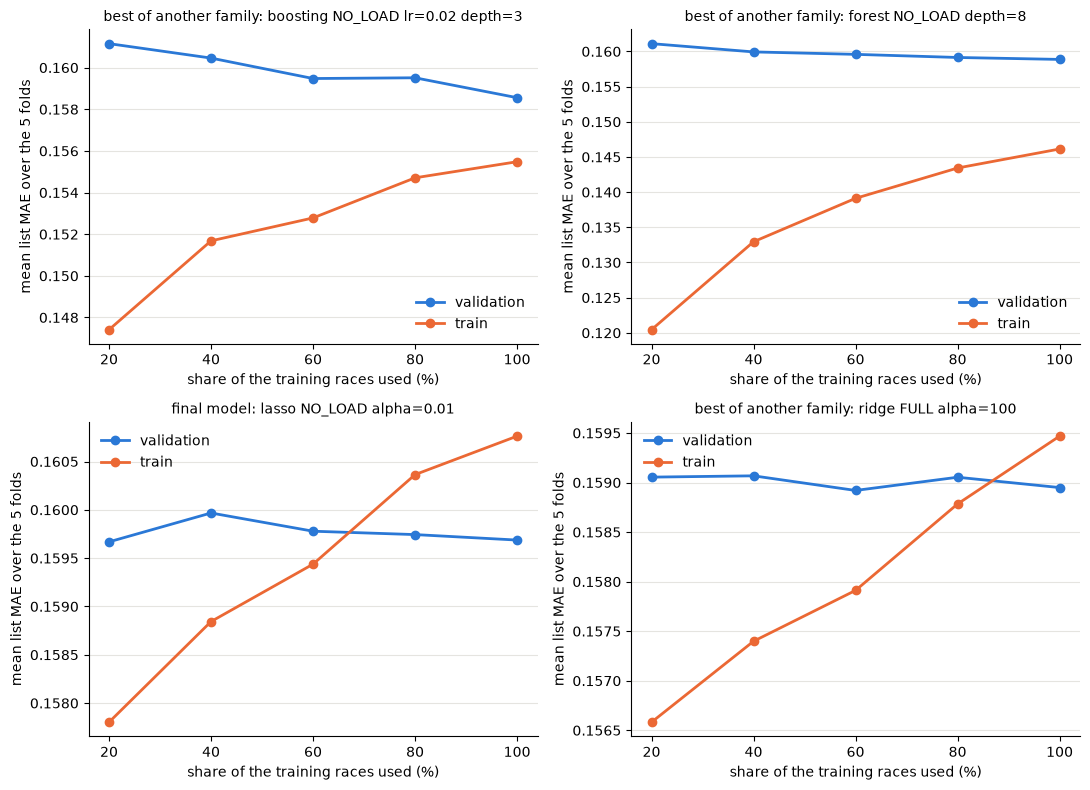

In [13]:
import matplotlib.pyplot as plt

curve = p.load_output("models_learning_curve")
names = list(curve["name"].unique())
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, name in zip(axes.flat, names):
    one = curve[curve["name"] == name]
    ax.plot(one["share"] * 100, one["val_list_mae"], color="#2a78d6", linewidth=2, marker="o", label="validation")
    ax.plot(one["share"] * 100, one["train_list_mae"], color="#eb6834", linewidth=2, marker="o", label="train")
    ax.set_xticks(one["share"] * 100)
    ax.set_xlabel("share of the training races used (%)")
    ax.set_ylabel("mean list MAE over the 5 folds")
    ax.set_title(one["role"].iloc[0] + ": " + name, fontsize=10)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5.8 The feature importances of the forest (first look only)

**Check: `feature_importances_` of the best forest (lowest mean validation list MAE over both input sets), fitted on all 10 training seasons, sorted.** An importance says which share of the total error reduction inside the trees came from splits on this input; the values add up to 1.

**This is a first look only.** The measure favours inputs with many different values (a percentile has thousands, a flag has 2): such an input offers more places to split. It splits the credit between inputs that overlap: when 2 inputs carry almost the same information, each tree takes one or the other, and both look less important than the information really is. And it is computed on the training rows, not on new rows. Expected: the past results (ski percentile, finish percentile, last place) at the top, the flags at the bottom.

In [14]:
table = p.load_output("models_importance")
df = p.load_features()
table["different_values"] = [df[name].nunique() for name in table["feature"]]
print(table["label"].iloc[0].upper(), ":", table["forest"].iloc[0], ", fitted on all training seasons")
print(table[["feature", "importance", "different_values"]].round(4).to_string(index=False))
print()
print("sum of the importances:", round(float(table["importance"].sum()), 4))

FIRST LOOK ONLY : forest NO_LOAD depth=8 , fitted on all training seasons
               feature  importance  different_values
         last3_ski_pct      0.3180             18765
      last3_finish_pct      0.2977             18838
        last_place_any      0.1735               122
       last_finish_pct      0.1065              3327
       last3_range_pct      0.0300             18833
      n_sprints_window      0.0254                20
    window_mean_misses      0.0209               416
        last3_miss_pct      0.0161             16356
window_miss_dispersion      0.0075              5846
            no_history      0.0044                 2

sum of the importances: 1.0


## 5.9 Sanity checks

**Check: ridge and lasso with the FULL inputs give the numbers of step 4.** They are the same models as in section 4, scored by the code of step 5. Expected: every score in every fold and part equals the saved step 4 value, at every alpha of both grids.

In [15]:
new = p.load_output("models_scores_per_fold")
old = p.load_output("baselines_scores_per_fold")
numbers = p.SCORES + ["list_mae_no_history", "list_mae_with_history"]
total = 0
different = 0
for family in ["ridge", "lasso"]:
    a = new[(new["family"] == family) & (new["inputs"] == "FULL")].sort_values(["value", "fold", "part"])
    b = old[old["model"] == family].sort_values(["alpha", "fold", "part"])
    x = a[numbers].to_numpy(dtype=float)
    y = b[numbers].to_numpy(dtype=float)
    total = total + x.size
    different = different + int((~np.isclose(x, y, rtol=0, atol=1e-12)).sum())
    print(family, ": lines compared", len(a), "and", len(b))
print("numbers compared:", total, "  different by more than 0.000000000001:", different)

ridge : lines compared 60 and 60
lasso : lines compared 50 and 50
numbers compared: 770   different by more than 0.000000000001: 0


**Check: all forest predictions lie between 0 and 1.** A tree predicts the mean of the targets of the training rows in a leaf, and a forest takes the mean over its trees: such a mean cannot leave the range of the targets. The cell checks 2 forests in all 5 folds, on the training and the validation part: the best forest and the forest without depth limit, both with the NO_LOAD inputs. Expected: 0 predictions outside. (Boosting has no such limit: it adds up corrections, so it can leave the range. The list metric only uses the order.)

In [16]:
df = p.load_features()
columns = p.INPUT_SETS["NO_LOAD"]
for depth in [8, p.NO_LIMIT]:
    outside = 0
    lowest, highest = 1.0, 0.0
    for val_season, train_part, val_part in p.make_folds(df):
        model = p.make_forest(depth)
        model.fit(train_part[columns], train_part[p.TARGET])
        for rows in [train_part, val_part]:
            pred = model.predict(rows[columns])
            outside = outside + int(((pred < 0) | (pred > 1)).sum())
            lowest, highest = min(lowest, float(pred.min())), max(highest, float(pred.max()))
    print(p.candidate_name("forest", "NO_LOAD", depth), " predictions outside 0 to 1:", outside,
          "  lowest:", round(lowest, 4), "  highest:", round(highest, 4))

forest NO_LOAD depth=8  predictions outside 0 to 1: 0   lowest: 0.0598   highest: 0.9517


forest NO_LOAD depth=None  predictions outside 0 to 1: 0   lowest: 0.0072   highest: 0.9886


**Check: a second run gives the same numbers.** The cell scores 3 candidates again on all 5 folds and compares with the saved file: the final model, the best forest and the best boosting candidate. Expected: the same numbers to 12 decimals. The forest computes its trees on several processor cores at once, and the order in which their predictions are added up can move the 16th decimal; this is not a real difference.

In [17]:
saved = p.load_output("models_scores_per_fold")
table = p.load_output("models_candidates")
names = [table[table["final_model"]]["name"].iloc[0], p.best_name(table, family="forest"), p.best_name(table, family="boosting")]
again = [tuple(table.set_index("name").loc[name, ["family", "inputs", "value", "learning_rate"]]) for name in names]
fresh = p.score_candidates(again)
numbers = p.SCORES + ["list_mae_no_history", "list_mae_with_history", "trees_used"]
both = fresh.merge(saved, on=["name", "fold", "part"], suffixes=("_now", "_saved"))
print("lines compared:", len(both), "(3 candidates x 5 folds x 2 parts)")
for name in names:
    one = both[both["name"] == name]
    a = one[[n + "_now" for n in numbers]].to_numpy(dtype=float)
    b = one[[n + "_saved" for n in numbers]].to_numpy(dtype=float)
    difference = np.where(np.isnan(a) & np.isnan(b), 0, np.abs(a - b))
    print(f"{name:<34} different by more than 0.000000000001: {int((difference > 1e-12).sum())} of {a.size}"
          f"   largest difference: {difference.max():.1e}")

  fold 1 of 5 done


  fold 2 of 5 done


  fold 3 of 5 done


  fold 4 of 5 done


  fold 5 of 5 done
lines compared: 30 (3 candidates x 5 folds x 2 parts)
lasso NO_LOAD alpha=0.01           different by more than 0.000000000001: 0 of 80   largest difference: 8.3e-17
forest NO_LOAD depth=8             different by more than 0.000000000001: 0 of 80   largest difference: 8.3e-17
boosting NO_LOAD lr=0.02 depth=3   different by more than 0.000000000001: 0 of 80   largest difference: 8.3e-17


**Check: no row from 2023/24 or later is loaded, and step 6 is locked.** Every function of step 5 gets its rows from `p.load_features()`, which drops the test seasons. The only function that reads the test seasons, `p.load_test_rows`, refuses as long as `TEST_UNLOCKED` is False. Expected: the latest season is 2022/23, only the 5 validation seasons in the saved score table, the same row counts for every candidate, and a refusal from `load_test_rows`.

In [18]:
df = p.load_features()
print("seasons in the table      :", sorted(df["season"].unique()))
print("rows of a test season     :", int(df["season"].isin(p.TEST_SEASONS).sum()))
scores = p.load_output("models_scores_per_fold")
print("validation seasons in the saved score table:", sorted(scores["val_season"].unique()))
print("different row counts between candidates   :", int((scores.groupby(["fold", "part"])["n_rows"].nunique() > 1).sum()))
print()
print("TEST_UNLOCKED:", p.TEST_UNLOCKED)
try:
    p.load_test_rows()
    print("load_test_rows read the test seasons")
except SystemExit as refusal:
    print("load_test_rows refused:", refusal)

seasons in the table      : ['1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']
rows of a test season     : 0
validation seasons in the saved score table: ['1819', '1920', '2021', '2122', '2223']
different row counts between candidates   : 0

TEST_UNLOCKED: False
load_test_rows refused: Step 6 is locked: TEST_UNLOCKED is False in pipeline.py. The test seasons were not read.


## 5.10 The robustness run

**Check: do the conclusions of step 5 hold with another split?** Added on 18 Nov. The same 5 validation seasons (2018/19 to 2022/23), but each one is predicted by a model trained only on the 5 seasons just before it (a rolling window), not on all earlier seasons. Exactly the 64 candidates of step 5, with the same pipelines, seeds, metric and selection rule; no refinement round and no grid extension. This run changes nothing: the final model stays the one of step 5. Command: `python pipeline.py robustness` (about 5 minutes); the cell shows the 6 saved tables that start with `robustness_`.

Fold 1 (2018/19) has exactly 5 seasons before it, so its training part is the same in both splits and its scores must be equal. The other folds train on fewer rows than in step 5 (about 9,000 instead of up to 16,600).

Expected if step 5 was not luck: the same best candidate and about the same SE, the same choice, the 4 families again close together, and still no clear gain from the load features.

In [2]:
selection = p.load_output("robustness_selection").iloc[0]
print("                       rolling window (5 seasons)          step 5 (all earlier seasons)")
print("1. best             :", f"{selection['best']:<36}", selection["step5_best"])
print("   its list MAE     :", f"{round(selection['best_mean'], 5):<36}", round(selection["step5_best_mean"], 5))
print("2. SE               :", f"{round(selection['se'], 5):<36}", round(selection["step5_se"], 5))
print("   threshold        :", f"{round(selection['threshold'], 5):<36}", round(selection["step5_threshold"], 5))
print("   eligible         :", f"{str(selection['n_eligible']) + ' of ' + str(selection['n_candidates']):<36}",
      selection["step5_n_eligible"], "of", selection["n_candidates"])
print("3. choice of the rule:", f"{selection['one_se_choice']:<35}", selection["final_model_of_step_5"])
print("   same model       :", selection["same_model"],
      "   its list MAE on the rolling window:", round(selection["one_se_choice_mean"], 5),
      "  raw rank:", selection["one_se_choice_raw_rank"], "of", selection["n_candidates"])

print()
print("4. best of each family, validation list MAE mean and std:")
groups = p.load_output("robustness_groups")
print(groups.round(5).to_string(index=False))

print()
print("5. with load minus without load (below 0: the load features help):")
comparisons = p.load_output("robustness_comparisons")
for index, line in comparisons.iterrows():
    folds = [line["diff_fold_" + str(number)] for number in range(1, 6)]
    print(f"   {line['comparison']:<36} mean {line['diff_mean']:+.5f}   SE {line['diff_se']:.5f}"
          f"   mean / SE {line['diff_mean'] / line['diff_se']:+.2f}   folds where load helps: {sum(v < 0 for v in folds)} of 5")
step5 = p.load_output("models_comparisons")
print("   step 5, for comparison:")
for index, line in step5.iterrows():
    folds = [line["diff_fold_" + str(number)] for number in range(1, 6)]
    print(f"   {line['comparison']:<36} mean {line['diff_mean']:+.5f}   SE {line['diff_se']:.5f}"
          f"   mean / SE {line['diff_mean'] / line['diff_se']:+.2f}   folds where load helps: {sum(v < 0 for v in folds)} of 5")

print()
per_fold = p.load_output("robustness_final_per_fold")
print("6.", per_fold["model"].iloc[0], ": rolling window against all earlier seasons, validation list MAE per fold:")
print(per_fold.drop(columns="model").round(5).to_string(index=False))
print("   mean:", round(per_fold["all_earlier_list_mae"].mean(), 5), "against", round(per_fold["rolling_window_list_mae"].mean(), 5))

                       rolling window (5 seasons)          step 5 (all earlier seasons)
1. best             : boosting NO_LOAD lr=0.02 depth=3     boosting NO_LOAD lr=0.02 depth=3
   its list MAE     : 0.15854                              0.15856
2. SE               : 0.00206                              0.00198
   threshold        : 0.1606                               0.16054
   eligible         : 54 of 64                             56 of 64
3. choice of the rule: lasso NO_LOAD alpha=0.01            lasso NO_LOAD alpha=0.01
   same model       : True    its list MAE on the rolling window: 0.15964   raw rank: 46 of 64

4. best of each family, validation list MAE mean and std:
  family                             best  val_list_mae_mean  val_list_mae_std                       step5_best  step5_val_list_mae_mean  step5_val_list_mae_std
   ridge              ridge FULL alpha=10            0.15884           0.00504             ridge FULL alpha=100                  0.15895                

# Section 6: The final test

This section scores the frozen final model on the test seasons (2023/24, 2024/25, 2025/26).

**History of the test seasons.** They were opened once before, on 16 Nov, with the earlier pipeline (commit 564d95e: ridge on the old features, scored with the old MAE). After that the features (17 Nov), the metric and the models (18 Nov) were changed. The run below is the single test of the new pipeline, done on 18 Nov.

**The final model is frozen.** Lasso with alpha 0.01 on the 10 NO_LOAD inputs, in the pipeline median fill, StandardScaler, Lasso (at most 10,000 rounds). It was chosen in step 5 by the one standard error rule. Nothing was changed after the test numbers were seen: not the model, not the inputs, not a setting, not a rule.

**The run.** `TEST_UNLOCKED` was set to True by hand in `pipeline.py`, then the command `python pipeline.py test` was run once. It fits 3 models on all 18,183 training rows (2013/14 to 2022/23): the final model, the constant (the mean of the target in the training rows) and the naive rule (`last3_finish_pct`, empty cells filled with its median in the training rows). Then it loads the test rows through `load_test_rows` (only the test command uses it) and scores the 3 models with the list metrics of section 3.

**Where the numbers come from.** The command saved its tables in `outputs/` (names that start with `test_`, no athlete in them) and the predictions per athlete in `data/test_predictions.csv` (not in git). The cells below read these files. Only the last check of 6.8 loads the test rows again, to show that the same frozen code gives the same numbers.

**What step 5 lets us expect.** A test list MAE of the final model close to its validation value of 0.1597. The 5 validation seasons ranged from 0.155 to 0.167, so a value in or near that range would be no surprise. The robustness run is now in 5.10.

All standard deviations are sample standard deviations (ddof = 1).

## 6.1 The test scores

**Check: the 3 models on the 3 test seasons together, next to their validation scores.** 5 scores each. Validation is the mean over the 5 folds: final model from step 5, constant and naive rule from step 4 (the same folds). Expected: a test list MAE of the final model close to 0.1597, and the same order as on validation: constant worst, naive rule in the middle, final model best. The constant must again give a list MAE of about 0.337 (a random order) and has no rank correlation.

In [2]:
table = p.load_output("test_vs_validation")
test = p.load_output("test_scores")
whole = test[test["scope"] == "all"].iloc[0]
print("final model:", p.candidate_name(p.FINAL_FAMILY, p.FINAL_INPUTS, p.FINAL_VALUE))
print("test rows:", int(whole["rows"]), "  test races:", int(whole["races"]))
print()
# 1 line per score, 2 columns per model: validation and test.
wide = pd.DataFrame(index=p.SCORES)
for model in ["constant", "naive", "final"]:
    one = table[table["model"] == model].set_index("score")
    wide[model + "_validation"] = one["validation"]
    wide[model + "_test"] = one["test"]
print(wide.round(5).to_string())
print()
final = table[(table["model"] == "final") & (table["score"] == "list_mae")].iloc[0]
print("test list MAE of the final model minus its validation list MAE:", round(final["test_minus_validation"], 5))
name = p.candidate_name(p.FINAL_FAMILY, p.FINAL_INPUTS, p.FINAL_VALUE)
print("validation list MAE of the final model in the 5 folds:",
      p.fold_values(p.load_output("models_scores_per_fold"), name).round(5))

final model: lasso NO_LOAD alpha=0.01
test rows: 4778   test races: 48

           constant_validation  constant_test  naive_validation  naive_test  final_validation  final_test
list_mae               0.33733        0.33924           0.17512     0.16241           0.15969     0.14963
list_rmse              0.41292        0.41436           0.22985     0.21408           0.20947     0.19792
list_r2               -1.00610       -1.01902           0.37819     0.46108           0.48343     0.53938
spearman                   NaN            NaN           0.68973     0.73039           0.74199     0.76973
top10                  0.10461        0.09167           0.49850     0.49375           0.52914     0.55417

test list MAE of the final model minus its validation list MAE: -0.01006
validation list MAE of the final model in the 5 folds: [0.16328 0.16661 0.15612 0.1572  0.15522]


## 6.2 Per season, and per race

**Check: list MAE and rank correlation of the 3 models in each test season.** Expected: the same order of the 3 models in every season, and season values that differ about as much as the validation seasons did (about 0.01 between the best and the worst season).

In [3]:
test = p.load_output("test_scores")
seasons = test[test["scope"] != "all"]
for score in ["list_mae", "spearman"]:
    print(score)
    print(seasons.pivot(index="scope", columns="model", values=score)[["constant", "naive", "final"]].round(5).to_string())
    print()
print("rows and races per season:")
print(seasons[seasons["model"] == "final"][["scope", "rows", "races"]].to_string(index=False))

list_mae
model  constant    naive    final
scope                            
2324    0.33179  0.15852  0.14507
2425    0.33948  0.16341  0.14758
2526    0.34601  0.16506  0.15595

spearman
model  constant    naive    final
scope                            
2324        NaN  0.74206  0.78473
2425        NaN  0.73211  0.77783
2526        NaN  0.71699  0.74664

rows and races per season:
scope  rows  races
 2324  1533     16
 2425  1615     16
 2526  1630     16


**Check: the list MAE of each of the 48 test races.** 1 line per race, no athlete. Expected: the final model better than the naive rule in most races, and no single race far away from the others. The column `number_by_list_mae` numbers the races from the lowest list MAE of the final model to the highest. 48 is even, so 2 races share the middle (24 and 25); number 24 is the story race of 6.6.

In [4]:
races = p.load_output("test_list_mae_per_race")
show = ["day", "place", "gender", "is_major_event", "rows", "list_mae_final", "list_mae_naive",
        "list_mae_constant", "number_by_list_mae"]
print(races[show].round(4).to_string(index=False))
print()
print("the 48 race list MAEs of the final model:")
print(races["list_mae_final"].describe().round(5).to_string())
print()
print("races where the final model is better than the naive rule:",
      int((races["list_mae_final"] < races["list_mae_naive"]).sum()), "of", len(races))

       day                   place gender  is_major_event  rows  list_mae_final  list_mae_naive  list_mae_constant  number_by_list_mae
2023-12-01              Oestersund     SW           False    99          0.1685          0.2093             0.3411                  42
2023-12-02              Oestersund     SM           False    97          0.1399          0.1689             0.3029                  15
2023-12-08              Hochfilzen     SM           False    97          0.1250          0.1276             0.3054                   2
2023-12-08              Hochfilzen     SW           False    89          0.1396          0.1579             0.3650                  14
2023-12-14             Lenzerheide     SW           False    83          0.1406          0.1600             0.3313                  16
2023-12-15             Lenzerheide     SM           False    93          0.1468          0.1512             0.3455                  25
2024-01-05                 Oberhof     SM           Fal

## 6.3 The 5 slices

**Check: where is the final model good and where not, compared with the naive rule?** The predicted list is made on the whole race first, then the rows are split into groups. For each group: rows, races, the mean absolute error and the mean signed error (predicted percentile from the list minus real percentile; above 0 means the athlete was predicted further back than the real finish).

**How to read the signed error.** In every race the list percentiles have the mean 0.5, and so do the real ones. So over whole races the signed error is about 0 for any model. Slices 1 and 3 hold whole races, so their signed error is about 0 for both models and says nothing. It only says something in slices 2, 4 and 5, which cut through the races.

Expected:

* 1) Championship sprints (World Championships and Olympics, 6 sprints) against the other sprints: about the same error.
* 2) Rows without history are harder. On validation (step 4) the list MAE was much higher without history.
* 3) Men against women: no expectation.
* 4) Real finish position. No list is perfect, so the real top 10 % can only be predicted too far back (signed error above 0) and the real bottom 10 % only too far forward (below 0). Their absolute error can still be lower than in the middle, because errors at the edges can only go one way.
* 5) `n_sprints_window` (0 to 3, 4 to 9, 10 or more): fewer recent sprints, older or thinner information, a higher error.

In [5]:
slices = p.load_output("test_slices")
for name in slices["slice"].unique():
    one = slices[slices["slice"] == name]
    table = one.pivot(index="group", columns="model", values=["mean_abs_error", "mean_signed_error"])
    table.columns = [score.replace("mean_", "") + "_" + model for score, model in table.columns]
    final = one[one["model"] == "final"].set_index("group")
    table.insert(0, "races", final["races"])
    table.insert(0, "rows", final["rows"])
    table = table.loc[one["group"].unique()]          # keep the order of the file
    print(name)
    print((table.round(4) + 0).to_string())
    print()

1) championship
                                  rows  races  abs_error_final  abs_error_naive  signed_error_final  signed_error_naive
group                                                                                                                  
World Championships and Olympics   561      6           0.1433           0.1612              0.0002              0.0002
other sprints                     4217     42           0.1505           0.1626              0.0002              0.0002

2) history
                                  rows  races  abs_error_final  abs_error_naive  signed_error_final  signed_error_naive
group                                                                                                                  
with history (no_history = 0)     4631     48           0.1481           0.1584             -0.0022              0.0067
without history (no_history = 1)   147     42           0.1970           0.2889              0.0760             -0.2043

3) gender
 

## 6.4 The 10 largest misses

**Check: the 10 rows where the final model was most wrong.** Athlete, race, date, the predicted percentile from the list and the real one, the place in the predicted list and the real place. This table has names, so it is shown here only and never saved in `outputs/` (terms of the IBU data). Expected: athletes who usually finish at the front and had 1 very bad race, or the other way round. A model that only knows the past cannot foresee a fall, a broken pole or 5 misses. If the same athlete or the same race came up many times, something would be wrong with the data.

In [6]:
rows = p.load_test_predictions()
worst = rows.sort_values("abs_error", ascending=False).head(10).copy()
worst["day"] = worst["start"].str[:10]
worst = worst.rename(columns={"list_pct_final": "pred_pct", "finish_pct": "real_pct"})
show = ["Name", "Nat", "place", "day", "gender", "pred_pct", "real_pct", "error",
        "pred_place", "real_place", "n_finishers", "no_history"]
print(worst[show].round(3).to_string(index=False))
print()
print("different athletes among the 10:", worst["IBUId"].nunique(), "  different races:", worst["race_id"].nunique())
print("predicted too far forward (real finish was worse):", int((worst["error"] < 0).sum()), "of 10")

               Name Nat                   place        day gender  pred_pct  real_pct  error  pred_place  real_place  n_finishers  no_history
   DAVIDOVA Marketa CZE      Antholz-Anterselva 2026-02-14     SW     0.089     0.889 -0.800           9          81           91           0
    SOERUM Vebjoern NOR              Hochfilzen 2025-12-12     SM     0.068     0.816 -0.748           8          85          104           0
     RICHARD Jeanne FRA                 Oberhof 2024-01-05     SW     0.792     0.073  0.719          77           8           97           1
   STROLIA Vytautas LTU                 Oberhof 2026-01-08     SM     0.252     0.961 -0.709          27         100          104           0
     ARNEKLEIV Juni NOR      Soldier Hollow, UT 2024-03-08     SW     0.075     0.774 -0.699           8          73           94           0
HAUSER Lisa Theresa AUT Annecy-Le Grand Bornand 2024-12-20     SW     0.163     0.859 -0.696          16          80           93           0
      

## 6.5 Permutation importance

**Check: how much does the final model need each input?** On the test rows, the values of 1 input are shuffled between the rows, so that this input no longer belongs to the right athlete. The list MAE is computed again. This is repeated 20 times (seed 42, the same seed for every input and group). Shown: the mean increase of the list MAE and its standard deviation. A big increase means the model needs the input.

Version a shuffles each of the 10 inputs alone. Version b shuffles the inputs of a group together, with the same new order of the rows: results (`last3_finish_pct`, `last_finish_pct`, `last_place_any`), skiing (`last3_ski_pct`), shooting (`last3_range_pct`, `last3_miss_pct`, `window_mean_misses`, `window_miss_dispersion`), experience (`n_sprints_window`, `no_history`).

Expected: the inputs with a lasso weight of 0 do not enter the prediction at all, so shuffling them must change nothing: an increase of exactly 0 in every repeat. Skiing far in front, as in the weights of step 4. The result inputs overlap, so the group can matter more than its inputs alone added up.

In [7]:
table = p.load_output("test_permutation")
print("list MAE of the final model on the test rows, nothing shuffled:", round(table["list_mae_not_shuffled"].iloc[0], 5))
print("repeats:", int(table["repeats"].iloc[0]))
for version in table["version"].unique():
    one = table[table["version"] == version]
    print()
    print(version)
    print(one[["name", "lasso_weight_zero", "list_mae_increase_mean", "list_mae_increase_std"]].round(5).to_string(index=False))

zero = table[table["lasso_weight_zero"]]
print()
print("lines with a lasso weight of 0:", len(zero), " ", ", ".join(zero["name"]))
print("all their increases exactly 0 (mean and std):",
      bool((zero["list_mae_increase_mean"] == 0).all() and (zero["list_mae_increase_std"] == 0).all()))
single = table[table["version"] == "a) each input alone"].set_index("name")["list_mae_increase_mean"]
group = table[table["version"] == "b) by group"].set_index("name")["list_mae_increase_mean"]
for name, members in p.INPUT_GROUPS.items():
    print(f"{name:<11} inputs alone, added up: {single[members].sum():.5f}   shuffled together: {group[name]:.5f}")

list MAE of the final model on the test rows, nothing shuffled: 0.14963
repeats: 20

a) each input alone
                  name  lasso_weight_zero  list_mae_increase_mean  list_mae_increase_std
         last3_ski_pct              False                 0.10094                0.00259
        last_place_any              False                 0.01408                0.00119
            no_history              False                 0.00654                0.00046
      last3_finish_pct              False                 0.00345                0.00066
       last3_range_pct              False                 0.00305                0.00047
    window_mean_misses              False                 0.00117                0.00025
        last3_miss_pct               True                 0.00000                0.00000
       last_finish_pct               True                 0.00000                0.00000
      n_sprints_window               True                 0.00000                0.00000
windo

## 6.6 The story figure

**Check: what does a typical race look like?** The 48 test sprints are sorted by the list MAE of the final model, from low to high, and number 24 is taken: a race in the middle, neither a good nor a bad one. The picture shows the place in the predicted list against the real place, 1 dot per athlete, no names. A dot on the dashed line is a perfect prediction. A dot below the line is an athlete who was predicted further forward than the real finish. The command saved the same picture as `outputs/test_story.png`. Expected: a cloud along the line, with a few dots far away.

story race: BT2425SWRLCP07SMSP Nove Mesto na Morave 2025-03-06  finishers: 94  list MAE: 0.14653  number 24 of 48


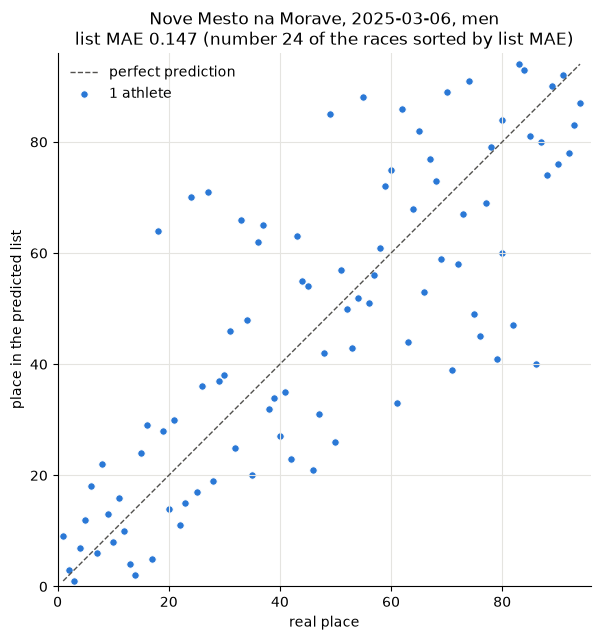

In [8]:
import matplotlib.pyplot as plt

races = p.load_output("test_list_mae_per_race")
story = races[races["story_race"]].iloc[0]
rows = p.load_test_predictions()
race = rows[rows["race_id"] == story["race_id"]]

print("story race:", story["race_id"], story["place"], story["day"], " finishers:", len(race),
      " list MAE:", round(story["list_mae_final"], 5), " number", int(story["number_by_list_mae"]), "of", len(races))
fig = p.draw_story(race, p.story_title(story))        # the same function that saved the file
plt.show()

**The same race as a table, with names.** Sorted by real place. Shown here only, not saved in `outputs/`.

In [9]:
races = p.load_output("test_list_mae_per_race")
story = races[races["story_race"]].iloc[0]
rows = p.load_test_predictions()
race = rows[rows["race_id"] == story["race_id"]].sort_values("real_place")
race = race.rename(columns={"list_pct_final": "pred_pct", "finish_pct": "real_pct"})
race["place_error"] = race["pred_place"] - race["real_place"]

print(story["place"], story["day"])
print(race[["real_place", "pred_place", "place_error", "Name", "Nat", "real_pct", "pred_pct", "no_history"]]
      .round(3).to_string(index=False))
print()
print("rank correlation in this race:", round(race["pred_place"].corr(race["real_place"], method="spearman"), 3))
print("athletes of the real top 10 that are in the predicted top 10:",
      int(((race["real_place"] <= 10) & (race["pred_place"] <= 10)).sum()))

Nove Mesto na Morave 2025-03-06
 real_place  pred_place  place_error                   Name Nat  real_pct  pred_pct  no_history
          1           9            8      JACQUELIN Emilien FRA     0.000     0.086           0
          2           3            1       GIACOMEL Tommaso ITA     0.011     0.022           0
          3           1           -2  BOE Johannes Thingnes NOR     0.022     0.000           0
          4           7            3            PERROT Eric FRA     0.032     0.065           0
          5          12            7      STROEMSHEIM Endre NOR     0.043     0.118           0
          6          18           12           NELIN Jesper SWE     0.054     0.183           0
          7           6           -1 FILLON MAILLET Quentin FRA     0.065     0.054           0
          8          22           14         CLAUDE Emilien FRA     0.075     0.226           0
          9          13            4        WRIGHT Campbell USA     0.086     0.129           0
        

## 6.7 The final weights

**Check: the weights of the final lasso, fitted on all 10 training seasons, sorted by size.** The inputs are scaled, so a weight says by how much the predicted percentile moves when the input goes up by 1 standard deviation. A positive weight means a higher value gives a worse predicted finish. A weight of exactly 0 means the lasso dropped the input. Expected: the same picture as in step 5 at alpha 0.01 (at most 7 nonzero weights in the folds): ski percentile first, then the past results and the no history flag. As in step 4, this is not causation, and overlapping inputs share their weight.

In [10]:
weights = p.load_output("test_weights")
print("alpha:", weights["alpha"].iloc[0], "  inputs:", len(weights),
      "  nonzero weights:", int((~weights["dropped"]).sum()),
      "  intercept:", round(weights["intercept"].iloc[0], 5),
      "  rounds used:", int(weights["rounds_used"].iloc[0]), "of", p.LASSO_MAX_ITER)
print()
print(weights[["feature", "weight", "dropped", "fill_median", "scale_mean", "scale_spread"]].round(5).to_string(index=False))

alpha: 0.01   inputs: 10   nonzero weights: 6   intercept: 0.49981   rounds used: 72 of 10000

               feature  weight  dropped  fill_median  scale_mean  scale_spread
         last3_ski_pct 0.12424    False      0.49403     0.49586       0.26852
        last_place_any 0.04928    False     47.00000    48.61926      28.87342
            no_history 0.03344    False      0.00000     0.03157       0.17485
      last3_finish_pct 0.02675    False      0.49262     0.49589       0.24915
       last3_range_pct 0.01812    False      0.49936     0.49682       0.24421
    window_mean_misses 0.01150    False      2.00000     2.04907       0.80609
        last3_miss_pct 0.00000     True      0.49238     0.49869       0.19114
       last_finish_pct 0.00000     True      0.49020     0.49354       0.28547
      n_sprints_window 0.00000     True      9.00000     8.95705       4.65231
window_miss_dispersion 0.00000     True      1.00000     1.06387       0.35433


## 6.8 Sanity checks

**Check: the row counts.** Expected: 18,183 training rows, 4,778 test rows in 48 races, 16 races in each test season, and 6 championship sprints.

In [11]:
df = p.load_features()
train = df[df["season"].isin(p.TRAIN_SEASONS)]
print("training rows:", len(train), "(expected", p.EXPECTED_TRAIN_ROWS, ")")

scores = p.load_output("test_scores")
whole = scores[(scores["scope"] == "all") & (scores["model"] == "final")].iloc[0]
print("test rows    :", int(whole["rows"]), "(expected", p.EXPECTED_TEST_ROWS, ")")
print("test races   :", int(whole["races"]), "(expected", p.EXPECTED_TEST_RACES, ")")
count = p.count_test()                      # the count function of step 3, 2 columns only
print("counted again with count_test: rows", len(count), " races", count["race_id"].nunique())

races = p.load_output("test_list_mae_per_race")
print()
print("races per test season:", races.groupby("season").size().to_dict())
print("rows in the race table:", int(races["rows"].sum()))
print("championship sprints :", int(races["is_major_event"].sum()), "(expected 6)")
print(races[races["is_major_event"]][["day", "place", "gender", "rows"]].to_string(index=False))

training rows: 18183 (expected 18183 )
test rows    : 4778 (expected 4778 )
test races   : 48 (expected 48 )
counted again with count_test: rows 4778  races 48

races per test season: {2324: 16, 2425: 16, 2526: 16}
rows in the race table: 4778
championship sprints : 6 (expected 6)
       day                place gender  rows
2024-02-09 Nove Mesto na Morave     SW    93
2024-02-10 Nove Mesto na Morave     SM    98
2025-02-14          Lenzerheide     SW    91
2025-02-15          Lenzerheide     SM    98
2026-02-13   Antholz-Anterselva     SM    90
2026-02-14   Antholz-Anterselva     SW    91


**Check: the training rows are all before the test rows.** Expected: the latest start of a training row is before the earliest start of a test row, and no race is in both parts.

In [12]:
df = p.load_features()
train = df[df["season"].isin(p.TRAIN_SEASONS)]
test = p.load_test_predictions()

print("latest training start:", train["start"].max())
print("earliest test start  :", test["start"].min())
print("training is before the test:", train["start"].max() < test["start"].min())
print("races in both parts        :", len(set(train["race_id"]) & set(test["race_id"])))
print("seasons of the training rows:", sorted(train["season"].unique()))
print("seasons of the test rows    :", sorted(test["season"].unique()))

latest training start: 2023-03-18 14:00:00+00:00
earliest test start  : 2023-12-01 13:45:00+00:00
training is before the test: True
races in both parts        : 0
seasons of the training rows: ['1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']
seasons of the test rows    : ['2324', '2425', '2526']


**Check: the fitted pipeline is the frozen final model.** The cell fits the pipeline again on the training rows (no test row is needed for this) and looks inside. Expected: 3 steps in the order fill, scale, lasso, alpha 0.01, at most 10,000 rounds, the 10 NO_LOAD inputs, none of the 3 load features, and the same weights as in the saved table.

In [13]:
df = p.load_features()
train = df[df["season"].isin(p.TRAIN_SEASONS)]
model = p.fit_final_model(train)

print("steps of the pipeline :", [name + " = " + type(step).__name__ for name, step in model.steps])
print("fill strategy         :", model.named_steps["fill"].strategy)
print("alpha                 :", model.named_steps["lasso"].alpha)
print("max rounds            :", model.named_steps["lasso"].max_iter)
print("number of inputs      :", model.named_steps["lasso"].n_features_in_)
print("inputs                :", list(model.feature_names_in_))
print("load features among them:", [name for name in model.feature_names_in_ if name in p.LOAD_FEATURES])
print("rows the model was fitted on:", len(train))

saved = p.load_output("test_weights").set_index("feature")["weight"]
now = pd.Series(model.named_steps["lasso"].coef_, index=model.feature_names_in_)
print("largest difference to the saved weights:", float((now - saved[now.index]).abs().max()))

steps of the pipeline : ['fill = SimpleImputer', 'scale = StandardScaler', 'lasso = Lasso']
fill strategy         : median
alpha                 : 0.01
max rounds            : 10000
number of inputs      : 10
inputs                : ['last3_finish_pct', 'last3_ski_pct', 'last3_range_pct', 'last3_miss_pct', 'last_finish_pct', 'n_sprints_window', 'last_place_any', 'window_mean_misses', 'window_miss_dispersion', 'no_history']
load features among them: []
rows the model was fitted on: 18183
largest difference to the saved weights: 8.326672684688674e-17


**Check: the same frozen code gives identical numbers.** This is the only cell of the lab book that loads the test rows. It calls the same functions as the command `python pipeline.py test`, with no change to the code, builds every table again and compares with the saved files. This only reproduces the numbers; nothing is chosen. Expected: 0 different numbers. The lasso has no random part, the list ties use the seed of each race, and the permutation importance uses a fixed seed. Numbers count as the same when they are equal to 12 decimals, because saving a number in a file and reading it back can move the last digit.

In [14]:
train, test = p.load_test_data()               # the test rows, loaded as the command does
tables = p.test_tables(train, test)            # fit, predict and build every table again

saved = {"scores": "test_scores", "versus_validation": "test_vs_validation",
         "races": "test_list_mae_per_race", "slices": "test_slices",
         "permutation": "test_permutation", "weights": "test_weights"}
for key, name in saved.items():
    columns = tables[key].select_dtypes("number").columns
    now = tables[key][columns].to_numpy(dtype=float)
    before = p.load_output(name)[columns].to_numpy(dtype=float)
    both_empty = np.isnan(now) & np.isnan(before)
    difference = np.where(both_empty, 0, np.abs(now - before))
    print(f"{name:<23} numbers: {now.size:>4}   different by more than 0.000000000001: "
          f"{int((difference > 1e-12).sum())}   largest difference: {difference.max():.1e}")

for column in ["pred_final", "list_pct_final"]:
    now = tables["predictions"][column].to_numpy()
    before = p.load_test_predictions()[column].to_numpy()
    print(f"{column:<23} numbers: {now.size:>4}   different by more than 0.000000000001: "
          f"{int((np.abs(now - before) > 1e-12).sum())}   largest difference: {np.abs(now - before).max():.1e}")
print("warnings in this run:", len(tables["warnings"]))

test_scores             numbers:   84   different by more than 0.000000000001: 0   largest difference: 1.1e-16
test_vs_validation      numbers:   45   different by more than 0.000000000001: 0   largest difference: 9.7e-17
test_list_mae_per_race  numbers:  240   different by more than 0.000000000001: 0   largest difference: 8.3e-17
test_slices             numbers:   96   different by more than 0.000000000001: 0   largest difference: 9.9e-17
test_permutation        numbers:   56   different by more than 0.000000000001: 0   largest difference: 9.3e-17
test_weights            numbers:   80   different by more than 0.000000000001: 0   largest difference: 2.2e-16
pred_final              numbers: 4778   different by more than 0.000000000001: 0   largest difference: 1.1e-16
list_pct_final          numbers: 4778   different by more than 0.000000000001: 0   largest difference: 1.1e-16
warnings in this run: 0


## 6.9 Who is in the test seasons?

**Describes the seasons, scores no model.**

First added on 16 Nov, after the first test, to look for a reason why the test seasons were easier to predict than the validation seasons. The test of 18 Nov shows the same (6.1), so the cell is kept. No model is fitted or scored here: the cell only counts nations, athletes and rows.

**Check: the field of each test season.** For 2023/24, 2024/25 and 2025/26: the number of nations with at least 1 sprint finisher, the number of athletes, the number and share of rows with no_history = 1, and the nations that have finishers in that season but had none in the 3 seasons before it. The 3 seasons before the test are shown in the same way, to compare. The rows of the test seasons come from `data/test_predictions.csv` (only the columns season, nation, athlete and no_history are used), the rows of the earlier seasons from `p.load_features()`.

In [15]:
columns = ["season", "Nat", "IBUId", "no_history"]
earlier = p.load_features()[columns]                 # seasons 2012/13 to 2022/23
test = p.load_test_predictions()[columns]            # the 3 test seasons, no prediction column
rows = pd.concat([earlier, test], ignore_index=True)

all_seasons = p.HISTORY_SEASONS + p.TRAIN_SEASONS + p.TEST_SEASONS      # in time order
lines = []
for season in all_seasons[-6:]:                      # the 3 seasons before the test, then the test
    one = rows[rows["season"] == season]
    position = all_seasons.index(season)
    before = rows[rows["season"].isin(all_seasons[position - 3:position])]    # the 3 seasons before
    new_nations = sorted(set(one["Nat"]) - set(before["Nat"]))
    lines.append({"season": season,
                  "test_season": season in p.TEST_SEASONS,
                  "nations": one["Nat"].nunique(),
                  "athletes": one["IBUId"].nunique(),
                  "rows": len(one),
                  "rows_no_history": int(one["no_history"].sum()),
                  "share_no_history": round(one["no_history"].mean(), 4),
                  "nations_not_in_the_3_seasons_before": ", ".join(new_nations) if new_nations else "none"})
print(pd.DataFrame(lines).to_string(index=False))

# The other direction: nations of the 3 seasons before the test that are in no test season.
before_test = rows[rows["season"].isin(["2021", "2122", "2223"])]
gone = sorted(set(before_test["Nat"]) - set(test["Nat"]))
print()
print("nations with finishers in 2020/21 to 2022/23 and none in the test seasons:", ", ".join(gone) if gone else "none")
for nation in gone:
    one = before_test[before_test["Nat"] == nation]
    print("  ", nation, ": rows per season", one.groupby("season").size().to_dict(),
          " athletes:", one["IBUId"].nunique())

season  test_season  nations  athletes  rows  rows_no_history  share_no_history nations_not_in_the_3_seasons_before
  2021        False       38       336  2060               60            0.0291                       GRL, NZL, RBU
  2122        False       38       356  2017               56            0.0278                            DEN, ROC
  2223        False       37       310  1572               57            0.0363                                none
  2324         True       32       300  1533               47            0.0307                                none
  2425         True       37       336  1615               57            0.0353                            ARG, BRA
  2526         True       34       334  1630               43            0.0264                                 BRT

nations with finishers in 2020/21 to 2022/23 and none in the test seasons: BIH, BLR, MKD, NZL, RBU, ROC, RUS, SRB, TUR
   BIH : rows per season {'2223': 1}  athletes: 1
   BLR : rows per 